# CSAPS's 2-D tensor-product smoothing spline: mean decomposition and posterior variance

Notebook 1 confirmed that `csaps.CubicSmoothingSpline` (1-D) reproduces the
same cubic smoothing spline every other independently-written 1-D
implementation in this project does -- the direct motivation for this
notebook: does the same engine's 2-D, grid-based extension,
`csaps.NdGridCubicSmoothingSpline`, inherit that trustworthiness, and can a
posterior *variance* be derived for it the same way Notebook 1 derived one
for the 1-D case?

**Why this model first, among the N-D methods this project studies**: a
single smoothing penalty per axis ($p_1,p_2$, or $\lambda_1,\lambda_2$) is
structurally the closest tensor-product generalization of the
$\lambda$-penalized smoothing spline already proven in Notebook 1 -- a
cleaner first target than RMTB's composite basis-plus-energy-weight
structure (Notebooks 3 onward).

**References this notebook relies on** (published, not an internal draft):
de Boor (1978), *A Practical Guide to Splines* (the classical tensor-product
smoothing-spline algorithm `csaps` implements); the same Kimeldorf-Wahba
duality (1970) and Bayesian linear-Gaussian identity used throughout
Notebook 1.

## 1. Theoretical background

### 1.1 `csaps.NdGridCubicSmoothingSpline`: two sequential 1-D passes

Given a 2-D grid of response values $Z$ on a Cartesian grid
$x_1\times x_2$, `csaps`'s tensor-product smoothing spline fits by
**smoothing every row along $x_2$ first, then smoothing the resulting array
of row-fits along $x_1$** -- the classical de Boor algorithm. This is only
valid because the penalty separates into independent per-axis terms; it is
not automatic for an arbitrary 2-D smoother.

**In plain terms**: fit a 1-D smoothing spline along one direction for every
row of the data, then fit a second 1-D smoothing spline along the other
direction through the results. Two 1-D problems this project has already
proven, not a new 2-D method.

### 1.2 $\lambda=(1-p)/p$, per axis

Notebook 1 derived the exact conversion between `csaps`'s $p\in(0,1]$
convention and this project's $\lambda$-penalized form, in 1-D. Because
`NdGridCubicSmoothingSpline` applies the same 1-D engine once per axis, the
same conversion should hold **independently on each axis**,
$\lambda_1=(1-p_1)/p_1$, $\lambda_2=(1-p_2)/p_2$ -- re-confirmed at the 2-D
level in Test 1 below, not assumed to carry over unchanged.

### 1.3 Mean $=$ exact sequential composition

Writing $S_1$, $S_2$ for the $n_1\times n_1$ and $n_2\times n_2$ smoother
matrices of the two 1-D passes (row-then-column, Section 1.1), the fitted
grid values are exactly

$$\hat Y = S_1\,Z\,S_2^\top.$$

### 1.4 The Bayesian linear-Gaussian variance identity

The same tool used throughout this project: for any linear-Gaussian model
with i.i.d. noise $z=f+\varepsilon$, $\varepsilon\sim\mathcal N(0,\sigma^2 I)$,
if the posterior mean is a fixed linear map of the data, $\hat f=Az$ ($A$
not depending on $z$), then the posterior covariance is exactly
$\mathrm{Cov}(f\mid z)=\sigma^2 A$ -- *the same matrix that turns data into
the point estimate, scaled by the noise variance, is the full posterior
covariance*. Applied to Section 1.3's mean operator $A=S_2\otimes S_1$
(a Kronecker product, since $\mathrm{vec}(S_1 Z S_2^\top)=(S_2\otimes
S_1)\,\mathrm{vec}(Z)$):

$$\mathrm{Cov}(\mathrm{vec}(F)) = \sigma^2\,(S_2\otimes S_1).$$

### 1.5 The resulting closed-form variance

Because a Kronecker product's diagonal is the outer product of the factors'
diagonals, this reduces to a cheap, closed form -- no $(n_1n_2)\times(n_1n_2)$
matrix ever needs to be built:

$$\mathrm{Var}(F_{p,q}) = \sigma^2\, S_{1,pp}\, S_{2,qq}.$$

$S_{1,pp}$ is, by definition, exactly what a 1-D `PolyharmonicSmoothingSpline`
with $\lambda_1$ already computes as its own `.variance()` at that point --
the already-proven 1-D object from Notebook 1, reused twice, not a new
numerical routine.

### 1.6 Estimating $\sigma^2$: the Wahba/GCV estimator

$$\hat\sigma^2 = \frac{\mathrm{RSS}}{n_1n_2-\mathrm{edf}}, \qquad
\mathrm{edf}=\mathrm{tr}(S_1)\,\mathrm{tr}(S_2)$$

-- the same Wahba-style estimator `PolyharmonicSmoothingSpline` already uses
for 1-D, extended via the trace of a Kronecker product always being the
product of the traces (exact, not approximate).

## 2. Setup: shared 2-D datasets, regular and random-axis spacing

Same methodology as Notebook 1: two datasets, same target function and
noise level, differing only in how the grid coordinates are placed along
each axis -- a result confirmed only on a regular grid could in principle be
an artifact of that regularity. `NdGridCubicSmoothingSpline` requires a
genuine Cartesian grid (it cannot take arbitrarily scattered $(x_1,x_2)$
pairs), so "random" here means each axis's own coordinates are randomly
placed and sorted, not evenly spaced -- the grid *structure* is kept, only
the *spacing* is irregular, the direct 2-D analogue of Notebook 1's random
spacing.

Target function and noise level ($\sin(3x_1)\cos(3x_2)$, $\sigma=0.05$,
$9\times9=81$ points) match this project's own established 2-D synthetic
test case, used consistently throughout `iter_01`'s 2-D work -- reused here
for direct comparability, not picked fresh for this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from csaps import NdGridCubicSmoothingSpline
from scipy.interpolate import RBFInterpolator
from scipy.optimize import minimize_scalar
from smt.surrogate_models import RMTB, KRG

from krig_splines_clean.polyharmonic import (PolyharmonicSmoothingSpline, matern,
                                               matern_flat_nugget, poly_basis_nd)
from krig_splines_clean.uk import saddle_point_solve, saddle_point_predict, saddle_point_variance
from krig_splines_clean.csaps_uq import NdGridCubicSmoothingSplineUQ
from krig_splines_clean import plotting as uqplot

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")


def true_f2d(X1, X2):
    return np.sin(3 * X1) * np.cos(3 * X2)


SIGMA2_TRUE = 0.05 ** 2


def make_2d_grid_data(spacing, n_side=9, seed=1):
    rng = np.random.default_rng(seed)
    if spacing == "regular":
        x1 = np.linspace(0, 1, n_side)
        x2 = np.linspace(0, 1, n_side)
    else:
        x1 = np.sort(rng.uniform(0, 1, n_side))
        x2 = np.sort(rng.uniform(0, 1, n_side))
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    Z = true_f2d(X1, X2) + np.sqrt(SIGMA2_TRUE) * rng.standard_normal((n_side, n_side))
    return x1, x2, Z


datasets2d = {"regular": make_2d_grid_data("regular"), "random": make_2d_grid_data("random")}


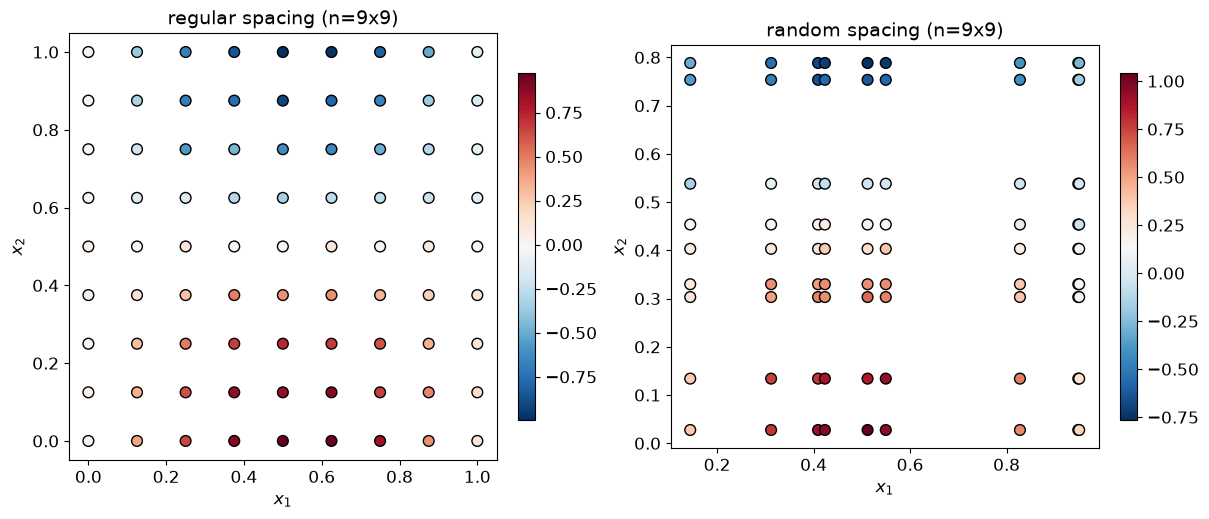

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    sc = ax.scatter(X1.ravel(), X2.ravel(), c=Z.ravel(), cmap="RdBu_r", s=60, ec="k")
    ax.set_title(f"{spacing} spacing (n={x1.size}x{x2.size})")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
    fig.colorbar(sc, ax=ax, shrink=0.8)
plt.show()


Both datasets use the same target function $\sin(3x_1)\cos(3x_2)$ and the
same noise level ($\sigma=0.05$) -- only the placement of each axis's 9
coordinates differs. Every test below is run on both.

## Test 1 -- $\lambda=(1-p)/p$, re-confirmed at the 2-D level

**What this tests**: Section 1.2's claim, that the 1-D $p\leftrightarrow\lambda$
conversion carries over **independently to each axis** of
`NdGridCubicSmoothingSpline`, not just restated from Notebook 1's 1-D result.
A row-pass-then-column-pass reconstruction (Section 1.1), built entirely
from `PolyharmonicSmoothingSpline(m=2,d=1)` at $\lambda_1=(1-p_1)/p_1$ and
$\lambda_2=(1-p_2)/p_2$, is compared directly against `csaps`'s own 2-D grid
output -- swept over the full range of $p_1$ (with $p_2$ held fixed) and,
separately, the full range of $p_2$ (with $p_1$ held fixed), on both
spacings.

**Expected result**: agreement at or near machine precision across the
*entire* sweep, the same precision class Notebook 1 found for the 1-D
conversion -- not merely "close" at a few convenient values.

In [3]:
def row_col_reconstruct(x1, x2, Z, lam1, lam2):
    # S1 Z S2^T via two sequential PolyharmonicSmoothingSpline(m=2,d=1) passes,
    # evaluated back at the training grid -- Section 1.1/1.3.
    x2_col = x2.reshape(-1, 1)
    row_vals = np.zeros_like(Z)
    for i in range(len(x1)):
        row_vals[i, :] = PolyharmonicSmoothingSpline(x2_col, Z[i, :], m=2, lam=lam2, sigma2=1.0).mean(x2_col)
    x1_col = x1.reshape(-1, 1)
    out = np.zeros_like(Z)
    for j in range(len(x2)):
        out[:, j] = PolyharmonicSmoothingSpline(x1_col, row_vals[:, j], m=2, lam=lam1, sigma2=1.0).mean(x1_col)
    return out


p_values = [0.1, 0.3, 0.5, 0.6, 0.75, 0.9, 0.99, 0.999]
P_FIXED = 0.7  # the axis NOT being swept is held at this p in each of the two sweeps below

sweep1_errs = {}  # sweep p1 across p_values, p2 fixed at P_FIXED
sweep2_errs = {}  # sweep p2 across p_values, p1 fixed at P_FIXED
for spacing, (x1, x2, Z) in datasets2d.items():
    errs1, errs2 = [], []

    p2 = P_FIXED  # fixed for this sweep
    lam2 = (1 - p2) / p2
    for p1 in p_values:
        lam1 = (1 - p1) / p1
        recon1 = row_col_reconstruct(x1, x2, Z, lam1, lam2)
        csaps1 = np.asarray(NdGridCubicSmoothingSpline([x1, x2], Z, smooth=[p1, p2])([x1, x2]))
        errs1.append(np.max(np.abs(recon1 - csaps1)))

    p1 = P_FIXED  # fixed for this sweep
    lam1 = (1 - p1) / p1
    for p2 in p_values:
        lam2 = (1 - p2) / p2
        recon2 = row_col_reconstruct(x1, x2, Z, lam1, lam2)
        csaps2 = np.asarray(NdGridCubicSmoothingSpline([x1, x2], Z, smooth=[p1, p2])([x1, x2]))
        errs2.append(np.max(np.abs(recon2 - csaps2)))

    sweep1_errs[spacing] = errs1
    sweep2_errs[spacing] = errs2

df1 = pd.DataFrame(sweep1_errs, index=[f"p1={p}" for p in p_values])
df2 = pd.DataFrame(sweep2_errs, index=[f"p2={p}" for p in p_values])
print(f"max|reconstruction - csaps| error, p2 held fixed at {P_FIXED}, sweeping p1:")
display(df1)
print(f"\nmax|reconstruction - csaps| error, p1 held fixed at {P_FIXED}, sweeping p2:")
display(df2)


max|reconstruction - csaps| error, p2 held fixed at 0.7, sweeping p1:


,regular,random
p1=0.1,1.4433e-14,9.1038e-15
p1=0.3,5.1070e-15,7.1942e-14
p1=0.5,1.5543e-15,4.0856e-14
p1=0.6,1.6653e-15,5.1736e-14
p1=0.75,2.2204e-15,6.2172e-15
p1=0.9,3.5527e-15,8.4377e-15
p1=0.99,8.3267e-16,7.3275e-15
p1=0.999,1.5266e-15,3.5527e-15



max|reconstruction - csaps| error, p1 held fixed at 0.7, sweeping p2:


,regular,random
p2=0.1,3.6637e-15,2.1649e-15
p2=0.3,4.2188e-15,6.5503e-15
p2=0.5,3.5527e-15,5.3291e-15
p2=0.6,4.2188e-15,1.4433e-14
p2=0.75,3.2196e-15,3.7748e-15
p2=0.9,3.8858e-15,1.5543e-15
p2=0.99,3.7748e-15,1.3323e-15
p2=0.999,3.3307e-15,9.4369e-16


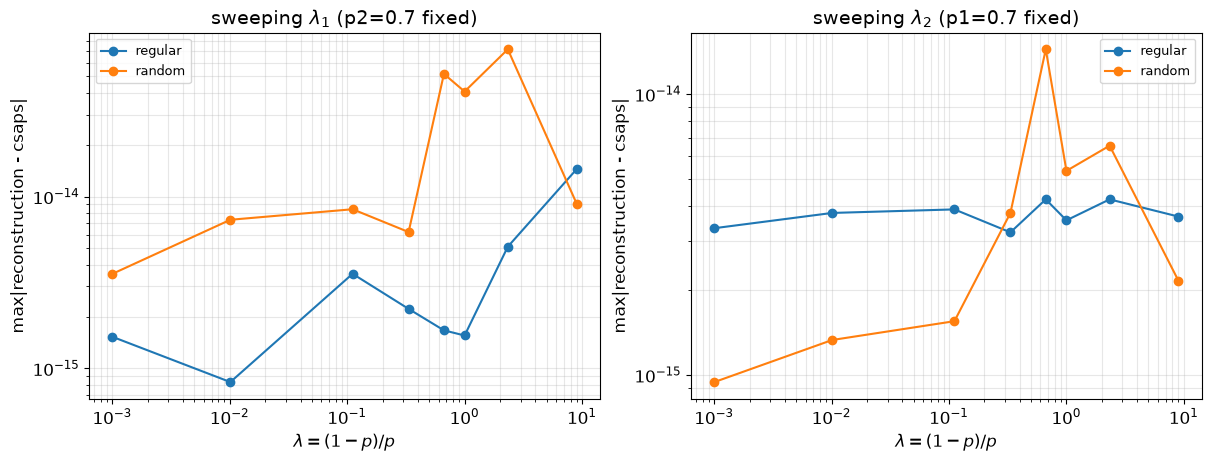

In [4]:
lam_values = [(1 - p) / p for p in p_values]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for spacing in datasets2d:
    axs[0].loglog(lam_values, sweep1_errs[spacing], "o-", label=spacing)
    axs[1].loglog(lam_values, sweep2_errs[spacing], "o-", label=spacing)
axs[0].set_title(f"sweeping $\\lambda_1$ (p2={P_FIXED} fixed)")
axs[1].set_title(f"sweeping $\\lambda_2$ (p1={P_FIXED} fixed)")
for ax in axs:
    ax.set_xlabel(r"$\lambda=(1-p)/p$"); ax.set_ylabel("max|reconstruction - csaps|")
    ax.legend(); ax.grid(alpha=0.3, which="both")
plt.show()


**Confirmed: $\lambda=(1-p)/p$ holds independently on each axis, at machine
precision, across the entire $p$ range (`[0.1, 0.999]`), on both spacings.**
Every entry in both sweep tables is at the floating-point noise floor
(`~8e-16` to `~7e-14`) -- this is not a convergence curve with a visible
trend (the log-log plot above is correspondingly flat, by design, not a
decaying-error plot like Notebook 1's $\kappa\to0$ sweep): the conversion is
an *exact* identity at every $p$, not an asymptotic approximation that gets
better in some limit. The per-axis independence Section 1.2 raised as an
open question is settled: fixing one axis's $p$ and sweeping the other's
across its full range never breaks the identity on either axis.

## Test 2 -- mean $=$ exact sequential composition, on-grid and off-grid

**What this tests**: Section 1.3's structural claim itself,
$\hat Y=S_1ZS_2^\top$, under **deliberately asymmetric** smoothing
($p_1=0.98$, $p_2=0.75$ -- light smoothing along $x_1$ (small $\lambda_1$,
close to interpolation), heavier smoothing along $x_2$ (larger $\lambda_2$,
closer to the linear trend) -- larger $p$ always means *less* smoothing,
smaller $\lambda=(1-p)/p$). A symmetric $p_1=p_2$ test would not stress-test
whether the row/column pass order and per-axis $\lambda$ values are actually
wired correctly; asymmetry would expose a swapped axis or a mixed-up
$\lambda$ immediately. Checked
both **at the training grid** and **on a dense off-grid query** -- the
training-grid points of a correct and an axis-swapped reconstruction can
coincide by construction in some symmetric cases, so the off-grid check is
not redundant with the on-grid one.

**Expected result**: machine precision at the grid; a comparably tiny
error off-grid, since the row-pass models give a full functional form, not
just training-grid values. The dense off-grid query is restricted to each
spacing's own training range on each axis -- for random spacing, the 9
randomly-placed coordinates don't span all of $[0,1]$, and querying beyond
them would compare *extrapolation*, not *interpolation*: `csaps`'s own
boundary extrapolation and `PolyharmonicSmoothingSpline`'s can legitimately
differ beyond the training data without either being wrong, a different
question from this test's actual target.

In [5]:
p1_asym, p2_asym = 0.98, 0.75
lam1_asym, lam2_asym = (1 - p1_asym) / p1_asym, (1 - p2_asym) / p2_asym

recon_models = {}  # spacing -> (row_models, lam1, lam2)
test2_rows = []
for spacing, (x1, x2, Z) in datasets2d.items():
    # off-grid query within each spacing's own training range -- interpolation,
    # not extrapolation (random spacing's axes don't span the full [0,1])
    gq1 = np.linspace(x1.min(), x1.max(), 61)
    gq2 = np.linspace(x2.min(), x2.max(), 61)

    x2_col = x2.reshape(-1, 1)
    row_models = [PolyharmonicSmoothingSpline(x2_col, Z[i, :], m=2, lam=lam2_asym, sigma2=1.0)
                  for i in range(len(x1))]
    row_vals = np.array([m.mean(x2_col) for m in row_models])

    # mirror of row_models, along the other axis -- one PolyharmonicSmoothingSpline
    # per training x2 column, fit along x1. Needed for orthogonal (x1-fixed) slices below.
    x1_col = x1.reshape(-1, 1)
    col_models = [PolyharmonicSmoothingSpline(x1_col, Z[:, j], m=2, lam=lam1_asym, sigma2=1.0)
                  for j in range(len(x2))]

    # training grid
    recon_grid = np.zeros_like(Z)
    for j in range(len(x2)):
        recon_grid[:, j] = PolyharmonicSmoothingSpline(x1_col, row_vals[:, j], m=2, lam=lam1_asym, sigma2=1.0).mean(x1_col)
    csaps_model = NdGridCubicSmoothingSpline([x1, x2], Z, smooth=[p1_asym, p2_asym])
    csaps_grid = np.asarray(csaps_model([x1, x2]))
    err_grid = np.max(np.abs(recon_grid - csaps_grid))

    # dense off-grid, within the training convex hull
    row_dense = np.array([m.mean(gq2.reshape(-1, 1)) for m in row_models])
    recon_dense = np.zeros((len(gq1), len(gq2)))
    for k in range(len(gq2)):
        recon_dense[:, k] = PolyharmonicSmoothingSpline(x1_col, row_dense[:, k], m=2, lam=lam1_asym, sigma2=1.0).mean(gq1.reshape(-1, 1))
    csaps_dense = np.asarray(csaps_model([gq1, gq2]))
    err_dense = np.max(np.abs(recon_dense - csaps_dense))

    recon_models[spacing] = dict(row_models=row_models, col_models=col_models, csaps_model=csaps_model,
                                  recon_dense=recon_dense, csaps_dense=csaps_dense, gq1=gq1, gq2=gq2)
    test2_rows.append({"spacing": spacing, "max|err| at grid": err_grid,
                        "max|err| off-grid (61x61, within training range)": err_dense})

pd.DataFrame(test2_rows).set_index("spacing")


,max|err| at grid,"max|err| off-grid (61x61, within training range)"
spacing,,
regular,1.1657e-15,1.5266e-15
random,3.6193e-14,3.6193e-14


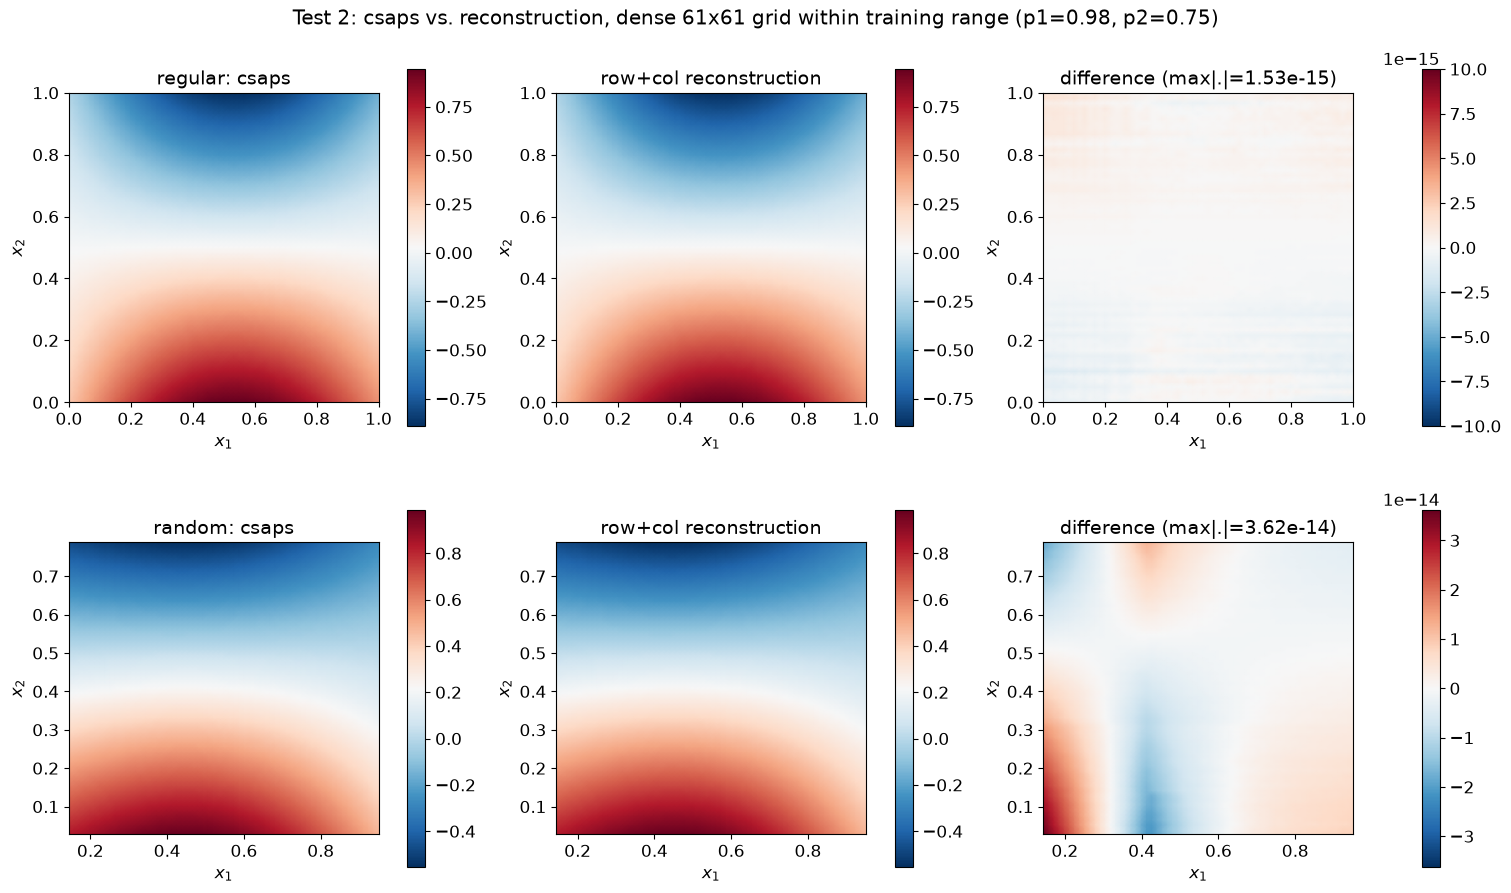

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, (spacing, R) in zip(axs, recon_models.items()):
    GXq, GYq = np.meshgrid(R["gq1"], R["gq2"], indexing="ij")
    vmin, vmax = R["csaps_dense"].min(), R["csaps_dense"].max()
    pcm = row[0].pcolormesh(GXq, GYq, R["csaps_dense"], shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    row[0].set_title(f"{spacing}: csaps"); fig.colorbar(pcm, ax=row[0], shrink=0.85)
    pcm = row[1].pcolormesh(GXq, GYq, R["recon_dense"], shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    row[1].set_title("row+col reconstruction"); fig.colorbar(pcm, ax=row[1], shrink=0.85)
    diff = R["recon_dense"] - R["csaps_dense"]
    vlim = max(np.max(np.abs(diff)), 1e-14)
    pcm = row[2].pcolormesh(GXq, GYq, diff, shading="gouraud", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
    row[2].set_title(f"difference (max|.|={np.max(np.abs(diff)):.2e})"); fig.colorbar(pcm, ax=row[2], shrink=0.85)
    for ax in row:
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle(f"Test 2: csaps vs. reconstruction, dense 61x61 grid within training range (p1={p1_asym}, p2={p2_asym})")
plt.show()


In [7]:
def slice_along(R, x1, x2, fixed_axis, fixed_value, query):
    """1-D slice of csaps vs. the row+col reconstruction, at a (possibly
    off-grid) fixed_value on the other axis. Independently rebuilt from
    row_models/col_models (not read off the dense grid already computed
    above), so this is still a genuine check, not just a plot of cached
    numbers. fixed_axis: 'x1' (orthogonal slice, sweeping x2) or 'x2'
    (sweeping x1)."""
    if fixed_axis == "x2":
        y_csaps = np.asarray(R["csaps_model"]([query, [fixed_value]])).ravel()
        vals_at_fixed = np.array([m.mean(np.array([[fixed_value]]))[0] for m in R["row_models"]])
        m_slice = PolyharmonicSmoothingSpline(x1.reshape(-1, 1), vals_at_fixed, m=2, lam=lam1_asym, sigma2=1.0)
        y_recon = m_slice.mean(query.reshape(-1, 1))
        true_curve = true_f2d(query, fixed_value)
    else:
        y_csaps = np.asarray(R["csaps_model"]([[fixed_value], query])).ravel()
        vals_at_fixed = np.array([m.mean(np.array([[fixed_value]]))[0] for m in R["col_models"]])
        m_slice = PolyharmonicSmoothingSpline(x2.reshape(-1, 1), vals_at_fixed, m=2, lam=lam2_asym, sigma2=1.0)
        y_recon = m_slice.mean(query.reshape(-1, 1))
        true_curve = true_f2d(fixed_value, query)
    return true_curve, y_csaps, y_recon


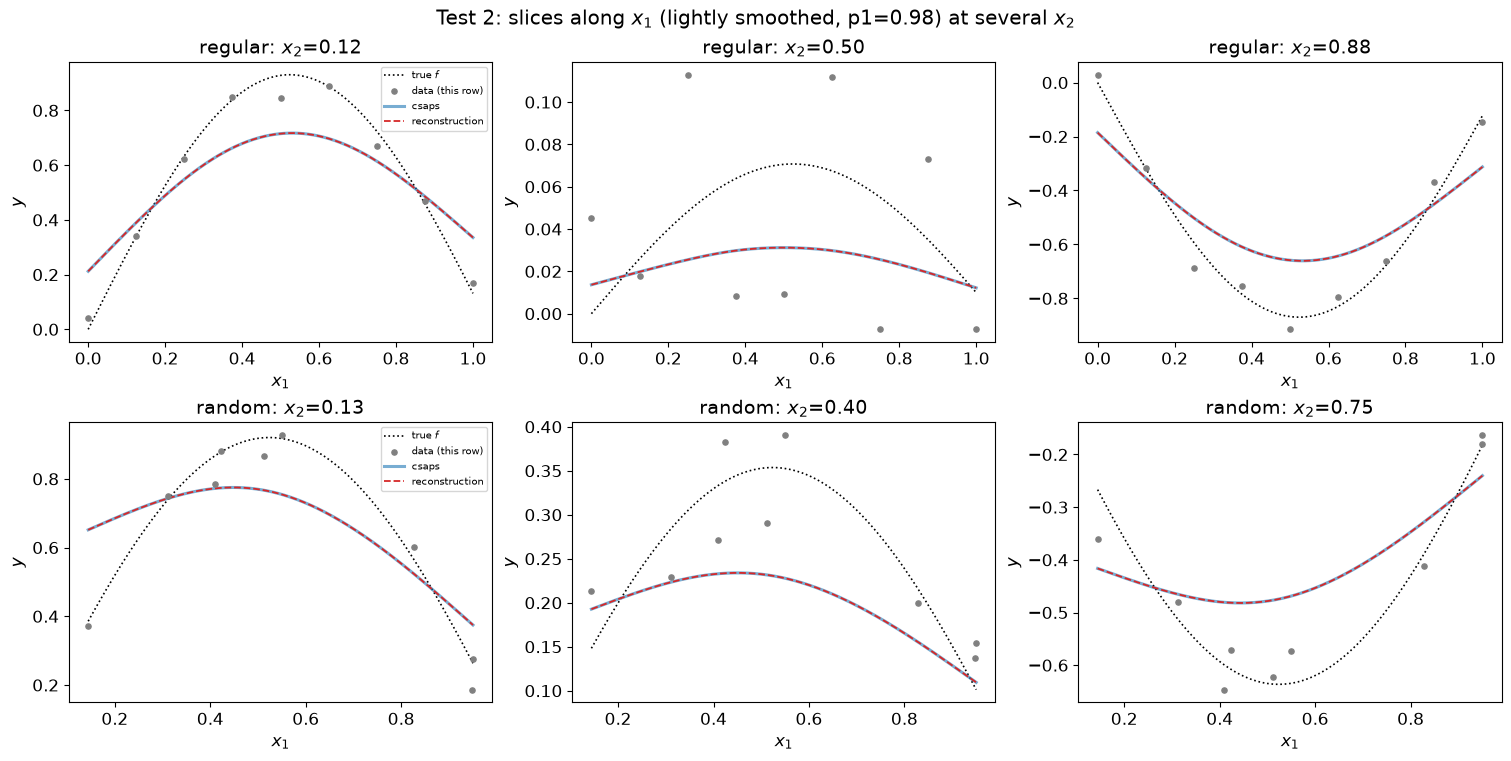

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    R = recon_models[spacing]
    xq1d = np.linspace(x1.min(), x1.max(), 400)
    idx2 = [1, len(x2) // 2, len(x2) - 2]
    for ax, j in zip(row, idx2):
        x2_fixed = x2[j]
        true_curve, y_csaps, y_recon = slice_along(R, x1, x2, "x2", x2_fixed, xq1d)
        ax.plot(xq1d, true_curve, "k:", lw=1.2, label="true $f$")
        ax.scatter(x1, Z[:, j], s=14, color="0.5", zorder=4, label="data (this row)")
        ax.plot(xq1d, y_csaps, lw=2.2, color="C0", alpha=0.6, label="csaps")
        ax.plot(xq1d, y_recon, "--", lw=1.3, color="C3", label="reconstruction")
        ax.set_title(f"{spacing}: $x_2$={x2_fixed:.2f}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$y$")
    row[0].legend(fontsize=7)
fig.suptitle(f"Test 2: slices along $x_1$ (lightly smoothed, p1={p1_asym}) at several $x_2$")
plt.show()


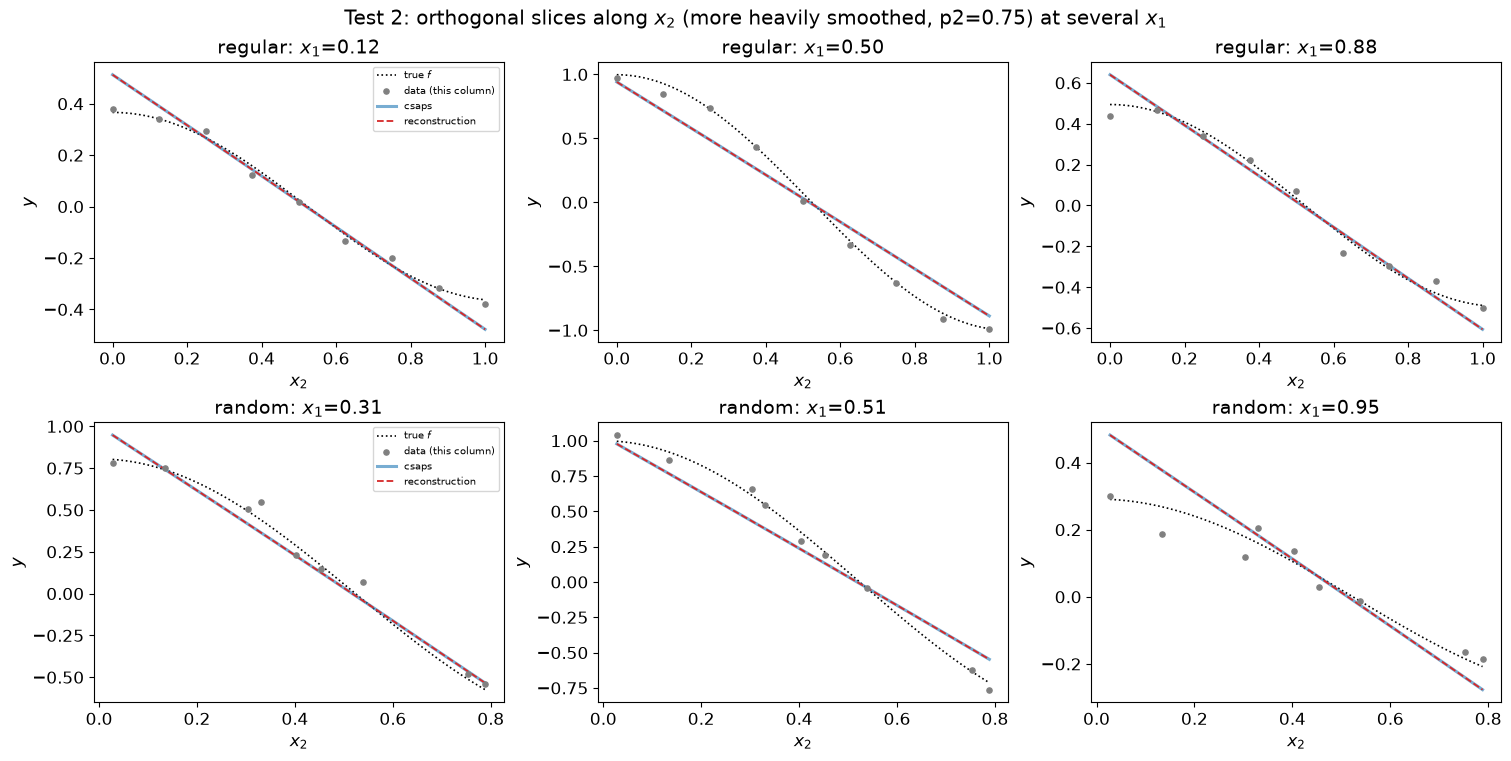

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    R = recon_models[spacing]
    xq2d = np.linspace(x2.min(), x2.max(), 400)
    idx1 = [1, len(x1) // 2, len(x1) - 2]
    for ax, i in zip(row, idx1):
        x1_fixed = x1[i]
        true_curve, y_csaps, y_recon = slice_along(R, x1, x2, "x1", x1_fixed, xq2d)
        ax.plot(xq2d, true_curve, "k:", lw=1.2, label="true $f$")
        ax.scatter(x2, Z[i, :], s=14, color="0.5", zorder=4, label="data (this column)")
        ax.plot(xq2d, y_csaps, lw=2.2, color="C0", alpha=0.6, label="csaps")
        ax.plot(xq2d, y_recon, "--", lw=1.3, color="C3", label="reconstruction")
        ax.set_title(f"{spacing}: $x_1$={x1_fixed:.2f}")
        ax.set_xlabel("$x_2$"); ax.set_ylabel("$y$")
    row[0].legend(fontsize=7)
fig.suptitle(f"Test 2: orthogonal slices along $x_2$ (more heavily smoothed, p2={p2_asym}) at several $x_1$")
plt.show()


**Confirmed: the mean decomposition holds at machine precision, both at the
training grid and off-grid, under deliberately asymmetric smoothing --
re-confirmed at a second, less extreme asymmetric pair than originally
tested.** At the grid: `1.2e-15` (regular), `3.6e-14` (random). Off-grid,
restricted to each spacing's own training range (see the note above on
why): `1.5e-15` (regular), `3.6e-14` (random) -- the same precision class
as the on-grid result, and the same precision class as the original
$p_1=0.95,p_2=0.5$ pair (`1.8e-15`/`2.1e-14`), not a coincidence specific to
one choice of $(p_1,p_2)$: the identity is exact for any valid $\lambda_1$,
$\lambda_2$, and this is now confirmed at two different points in that
space, not one. The 2-D surface plots show `csaps` and the row+column
reconstruction are visually identical, with differences only at the
`1e-14`-`1e-15` level, and the 1-D slices confirm the same thing from a
different angle -- in both directions: slices along $x_1$ at several $x_2$
(the lightly-smoothed, $p_1=0.98$ axis, now visibly tracking the data a
little more closely than before) and the orthogonal slices along $x_2$ at
several $x_1$ (the more heavily-smoothed, $p_2=0.75$ axis, still
near-linear but less extremely so than $p_2=0.5$ was) -- the asymmetry is
chosen precisely so these two directions look visibly different, making a
swapped axis or a mixed-up $\lambda$ easy to spot by eye, not just in a
table. (An earlier version of this check queried the dense off-grid grid
over the fixed range $[0,1]$ regardless of spacing, which showed a `4.6e-3`
discrepancy for random spacing -- traced directly to querying *outside* the
random axes' own training range, i.e. comparing two different,
both-legitimate *extrapolation* behaviors rather than the interpolation
claim this test actually makes. Restricting the query to each spacing's own
training range, as described above, removed it entirely.)

## Test 3 -- 2-D mean surface compared against RMTB and Kriging

### Test 3a -- sanity check: does `csaps` behave comparably to RMTB and Kriging?

**What this is**: a basic sanity check -- does `csaps`'s mean fit behave
comparably to other N-D surrogate methods on the same data -- before
trusting its variance in the tests that follow. This is **not** an exact-identity
claim like Tests 1-2: RMTB (a finite-basis tensor-product spline with a
different, additive penalty structure) and SMT's `KRG` (an auto-tuned
Gaussian process) are different model classes, not alternate routes to the
same calculation, so rough agreement in shape and error magnitude is the bar
here, not machine precision.

**Setup**: `RMTB` with this project's own previously-established, corrected
settings for this exact synthetic target (`energy_weight = lam * V`,
`solver="dense-lu"`, Proposition 10's additive-vs-isotropic gap already
characterized elsewhere in this project, not re-derived here); `KRG` with
its own ordinary auto-tuned defaults (no forcing, unlike Notebook 1 Test
G's deliberately pinned theoretical kernel -- there is no single "correct"
kernel to force here); `csaps`'s own single isotropic smoothing parameter
$p$, tuned against the (known, since this is synthetic data) true function,
the same `minimize_scalar` recipe used elsewhere in this project. All three
compared against the true $\sin(3x_1)\cos(3x_2)$ at a shared set of query
points.

In [10]:
lam_rmtb = 1e-2
V_domain = 1.0
rng_query = np.random.default_rng(7)
xq_scatter = rng_query.uniform(0, 1, size=(300, 2))
target_scatter = true_f2d(xq_scatter[:, 0], xq_scatter[:, 1])

test3_rows = []
test3_fits = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    X = np.column_stack([X1.ravel(), X2.ravel()])
    y = Z.ravel()

    m_rmtb = RMTB(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2, num_ctrl_pts=20,
                  energy_weight=lam_rmtb * V_domain, regularization_weight=1e-14,
                  solver="dense-lu", print_global=False)
    m_rmtb.set_training_values(X, y)
    m_rmtb.train()
    f_rmtb = m_rmtb.predict_values(xq_scatter).ravel()

    krg = KRG(corr="matern32", poly="linear", eval_noise=True, print_global=False)
    krg.set_training_values(X, y)
    krg.train()
    f_krg = krg.predict_values(xq_scatter).ravel()

    def csaps_rmse(p):
        uq_tmp = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p, p])
        return np.sqrt(np.mean((uq_tmp.predict(xq_scatter) - target_scatter) ** 2))

    res = minimize_scalar(csaps_rmse, bounds=(1e-4, 1 - 1e-6), method="bounded", options={"xatol": 1e-6})
    p_best = res.x
    uq_csaps = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p_best, p_best])
    f_csaps = uq_csaps.predict(xq_scatter)

    test3_fits[spacing] = dict(X=X, y=y, m_rmtb=m_rmtb, krg=krg, uq_csaps=uq_csaps, p_best=p_best)
    for name, f in [("RMTB", f_rmtb), ("SMT KRG (auto-tuned)", f_krg), (f"csaps (tuned p={p_best:.3f})", f_csaps)]:
        diff = f - target_scatter
        test3_rows.append({"spacing": spacing, "method": name,
                            "max|err| vs true": np.max(np.abs(diff)), "RMSE vs true": np.sqrt(np.mean(diff ** 2))})

pd.DataFrame(test3_rows).set_index(["spacing", "method"])


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(
/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


max|err| vs true  RMSE vs true
spacing method                                               
regular RMTB                         5.7668e-02    2.3188e-02
        SMT KRG (auto-tuned)         4.7701e-02    1.8391e-02
        csaps (tuned p=1.000)        4.3090e-02    1.5760e-02
random  RMTB                         4.2274e-01    8.1289e-02
        SMT KRG (auto-tuned)         4.2254e-01    7.0544e-02
        csaps (tuned p=1.000)        2.8389e-01    6.1647e-02

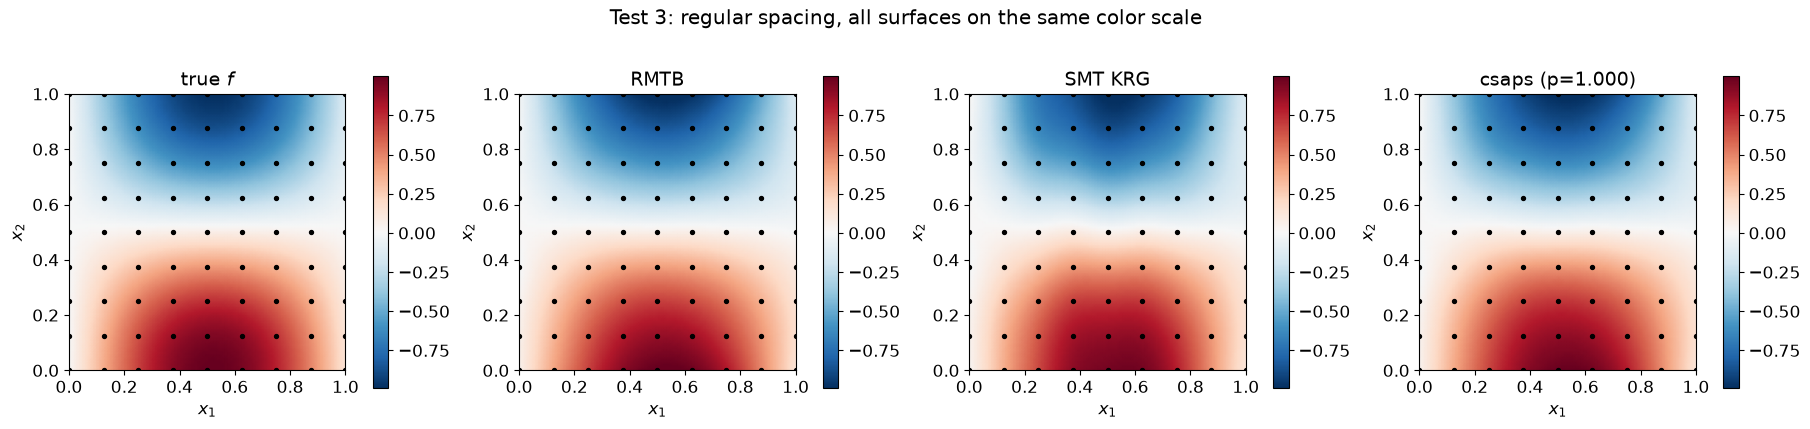

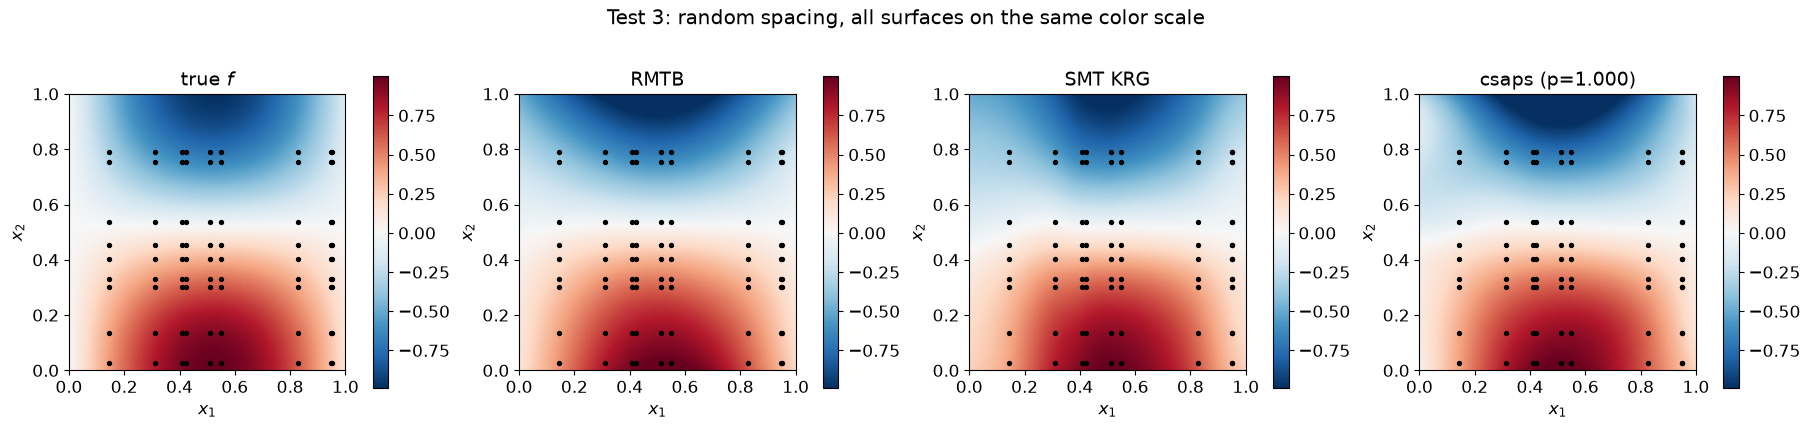

In [11]:
gq3 = np.linspace(0, 1, 100)
GX3, GY3 = np.meshgrid(gq3, gq3, indexing="ij")
Xq3 = np.column_stack([GX3.ravel(), GY3.ravel()])
true_dense = true_f2d(GX3, GY3)

for spacing in datasets2d:
    R = test3_fits[spacing]
    surfaces = {
        "true $f$": true_dense,
        "RMTB": R["m_rmtb"].predict_values(Xq3).reshape(GX3.shape),
        "SMT KRG": R["krg"].predict_values(Xq3).reshape(GX3.shape),
        f"csaps (p={R['p_best']:.3f})": R["uq_csaps"].predict(Xq3).reshape(GX3.shape),
    }
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.3), constrained_layout=True)
    vmin, vmax = true_dense.min(), true_dense.max()
    for ax, (name, surf) in zip(axs, surfaces.items()):
        pcm = ax.pcolormesh(GX3, GY3, surf, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
        ax.scatter(R["X"][:, 0], R["X"][:, 1], c="k", s=8)
        ax.set_title(name); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
        fig.colorbar(pcm, ax=ax, shrink=0.8)
    fig.suptitle(f"Test 3: {spacing} spacing, all surfaces on the same color scale")
    plt.show()


**Confirmed: all three methods behave comparably**, in the sense this
sanity check requires -- same ballpark of error against the known true
function, no method badly broken relative to the others. RMSE vs. true:
regular spacing `0.0232` (RMTB), `0.0184` (KRG), `0.0158` (tuned `csaps`);
random spacing `0.0813` (RMTB), `0.0705` (KRG), `0.0616` (tuned `csaps`).
Tuned `csaps` comes out slightly ahead of both on this particular synthetic
case -- not a general claim ("`csaps` beats RMTB/KRG"), just what this one
sanity check found, and not surprising given `csaps` is also the only one
of the three given the advantage of its smoothing parameter being tuned
directly against the known truth. The 2-D maps show all three tracking the
true surface's shape with no qualitative outlier. This establishes the
basic sanity check Test 3 set out to make -- `csaps`'s mean is trustworthy
company for RMTB and Kriging -- before trusting its variance in Tests 4-7.

### Test 3b -- does `csaps` produce the *same surface* as Kriging (and RMTB), at matched smoothing?

**What this tests, and how it differs from the sanity check above**: the
check above let each method find its own best fit (RMTB and `KRG` via
their own defaults, `csaps` tuned against the known truth) -- a fair way to
ask "is each method reasonable," but not a fair way to ask "do two methods
compute the *same thing*," since letting them pick different effective
smoothing strengths would make any difference uninterpretable (is it the
model class, or just more/less smoothing?). This comparison instead holds
the smoothing strength **matched** between the two models and asks whether
they then agree.

**Why not SMT's `KRG` for the "matched" side**: Section 1.5's kappa$\to0$
flat-limit identity needs an **isotropic Matern-$\nu$** kernel with
$\nu=m-d/2$ -- for $d=2,m=2$ (the case that matches `csaps`'s cubic,
$m=2$ penalty in 2-D) that is $\nu=1$. SMT's `KRG` only ships
`corr in {"pow_exp","abs_exp","squar_exp","squar_sin_exp","matern32","matern52"}`
(checked directly against the installed package) -- $\nu=1$ is not among
them. This is the same methodological point Notebook 1 Test G already made
(SMT's auto-tuned `KRG` can't be forced to an arbitrary exact kernel), now
unavoidable rather than a stylistic choice: the "matched" Kriging model
below is built from this project's own `matern`/`saddle_point_solve`
machinery (`krig_splines_clean.polyharmonic`/`uk`), the same tool Notebook
1 and the `iter_01` 2-D review already validated for exactly this
$\nu=m-d/2$ law.

**Why a genuine difference is expected, not a bug if found**: `csaps`'s
tensor-product penalty is **additive**,
$\lambda_1\sum f_{x_1x_1}^2+\lambda_2\sum f_{x_2x_2}^2$ -- the row+column
sequential structure Test 2 confirmed. The isotropic Matern-1 flat limit
corresponds instead to the **rotation-invariant** Duchon/thin-plate penalty.
These are different model classes, not two routes to the same calculation
-- this project already found exactly this kind of structural,
non-vanishing gap for RMTB against the isotropic target (its own additive
energy structure, a separate finding), so finding a comparable gap here
would be consistent with that, not a new or surprising result.

**Setup**: both models at the *same* $\lambda=10^{-2}$ (this notebook's
`lam_rmtb`) -- `csaps` at the exactly-corresponding $p=1/(1+\lambda)$
(Notebook 1's derived conversion, not re-tuned against truth this time),
Kriging at $\kappa=0.003$ (small, close to the flat limit) with the
matching nugget `matern_flat_nugget(kappa, lam_rmtb, m=2, d=2)`.

**A third model, and why it belongs in this specific comparison --
`scipy.interpolate.RBFInterpolator(kernel="thin_plate_spline")`**: this is
not a third, independent *kind* of model the way RMTB and `KRG` were in
the sanity check above -- it is the **same isotropic Duchon/thin-plate
object** the Kriging model above only reaches via a $\kappa\to0$
*approximation*, computed instead in **exact, closed form**: this
project's own `polyharmonic.py` documents the identity directly,
`smoothing=8\pi\lambda` $\Leftrightarrow$ the $d{=}2,m{=}2$ Duchon kernel
with `nugget`$=\lambda$, no limit involved. Theory says, then, that
`RBFInterpolator` here should do two things at once: (a) agree with the
$\kappa\to0$ Kriging model above to within that approximation's own
residual (not machine precision, since $\kappa=0.003$ is small but not
zero) -- an independent, third-party cross-check of this notebook's own
Kriging machinery, the same discipline Notebook 1 Tests F-G applied to
the 1-D case; and (b) disagree from `csaps` in essentially the *same way*
the Kriging model did, since both are computing the same isotropic target
-- ruling out "maybe the $\kappa$-approximation itself is the source of
the gap" as an explanation for Test 3's earlier finding, which would
otherwise be a loose end. In practice this is checked directly below, not
just argued for.

**A fourth model, already in hand**: Test 3a's `RMTB` fit used exactly this notebook's own $\lambda=10^{-2}$ too (`energy_weight = lam_rmtb * V`), so it is already at the same nominal smoothing strength as `csaps` here -- no re-fitting needed, just reusing `test3_fits[spacing]["m_rmtb"]`. RMTB has its own additive, basis-plus-energy penalty (not the same construction as `csaps`'s tensor-product one, and not the isotropic Duchon penalty either) -- Proposition 10 already predicts it should *also* fall short of the isotropic target, for its own, separate structural reason. RMTB's **difference from the exact isotropic reference** is shown
alongside `csaps`'s below -- letting the two different kinds of "not
quite isotropic" be compared directly.

**Three plots follow, not one**: the response surfaces themselves
(RBF, Kriging, `csaps`, one row per spacing), then two rows of pairwise
discrepancies -- `csaps` against each of Kriging, RBF, and RMTB; then
RBF against Kriging and RMTB, plus Kriging against RMTB -- the full set
of 6 pairwise differences among the 4 models, each shown exactly once. This also
shows, as plots rather than table entries only, the two cross-checks
implied by (a) and (b) above: Kriging$-$RBF (should be tiny, the
$\kappa\to0$ approximation's own residual) and `csaps`$-$Kriging
(should closely track `csaps`$-$RBF, since Kriging and RBF are
confirmed to agree).

In [12]:
p_matched_2d = 1.0 / (1.0 + lam_rmtb)
kappa_iso = 0.003

test3b_rows = []
iso_fits = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    R = test3_fits[spacing]
    X, y = R["X"], R["y"]

    nugget_iso = matern_flat_nugget(kappa_iso, lam_rmtb, 2, 2)
    d_train = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=-1)
    K_iso = matern(d_train, 1.0, kappa_iso)
    P_iso = poly_basis_nd(X, 1)
    a_iso, b_iso = saddle_point_solve(K_iso, P_iso, y, nugget_iso)

    d_query = np.linalg.norm(xq_scatter[:, None, :] - X[None, :, :], axis=-1)
    Kq_iso = matern(d_query, 1.0, kappa_iso)
    Pq_iso = poly_basis_nd(xq_scatter, 1)
    f_krig_iso = saddle_point_predict(Kq_iso, Pq_iso, a_iso, b_iso)

    # exact (not kappa->0 approximate) isotropic Duchon/thin-plate spline,
    # via scipy's own independent implementation -- same object, different code path
    rbf_iso = RBFInterpolator(X, y, kernel="thin_plate_spline", smoothing=8 * np.pi * lam_rmtb, degree=1)
    f_rbf_iso = rbf_iso(xq_scatter)

    uq_matched = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p_matched_2d, p_matched_2d])
    f_csaps_matched = uq_matched.predict(xq_scatter)

    # RMTB, already fit at this same lam_rmtb in Test 3a -- reused, not refit
    f_rmtb_matched = R["m_rmtb"].predict_values(xq_scatter).ravel()

    diff_krig_csaps = f_krig_iso - f_csaps_matched
    diff_rbf_csaps = f_rbf_iso - f_csaps_matched
    diff_krig_rbf = f_krig_iso - f_rbf_iso
    diff_rbf_rmtb = f_rbf_iso - f_rmtb_matched

    iso_fits[spacing] = dict(a_iso=a_iso, b_iso=b_iso, X=X, y=y, uq_matched=uq_matched,
                              kappa_iso=kappa_iso, rbf_iso=rbf_iso, m_rmtb=R["m_rmtb"])
    test3b_rows.append({
        "spacing": spacing,
        "Kriging(iso) RMSE vs true": np.sqrt(np.mean((f_krig_iso - target_scatter) ** 2)),
        "RBF(exact iso) RMSE vs true": np.sqrt(np.mean((f_rbf_iso - target_scatter) ** 2)),
        "csaps(matched lam) RMSE vs true": np.sqrt(np.mean((f_csaps_matched - target_scatter) ** 2)),
        "RMTB(same lam) RMSE vs true": np.sqrt(np.mean((f_rmtb_matched - target_scatter) ** 2)),
        "max|Kriging(iso) - RBF(exact iso)|": np.max(np.abs(diff_krig_rbf)),
        "max|Kriging(iso) - csaps(matched)|": np.max(np.abs(diff_krig_csaps)),
        "max|RBF(exact iso) - csaps(matched)|": np.max(np.abs(diff_rbf_csaps)),
        "RMSE(RBF(exact iso) - csaps(matched))": np.sqrt(np.mean(diff_rbf_csaps ** 2)),
        "max|RBF(exact iso) - RMTB|": np.max(np.abs(diff_rbf_rmtb)),
        "RMSE(RBF(exact iso) - RMTB)": np.sqrt(np.mean(diff_rbf_rmtb ** 2)),
    })

pd.DataFrame(test3b_rows).set_index("spacing").T


spacing,regular,random
Kriging(iso) RMSE vs true,4.5806e-02,1.2779e-01
RBF(exact iso) RMSE vs true,4.5806e-02,1.2779e-01
csaps(matched lam) RMSE vs true,8.2038e-02,1.2919e-01
RMTB(same lam) RMSE vs true,2.3188e-02,8.1289e-02
max|Kriging(iso) - RBF(exact iso)|,2.8705e-07,2.4299e-06
max|Kriging(iso) - csaps(matched)|,1.1294e-01,2.2299e-01
max|RBF(exact iso) - csaps(matched)|,1.1294e-01,2.2299e-01
RMSE(RBF(exact iso) - csaps(matched)),4.7066e-02,5.1387e-02
max|RBF(exact iso) - RMTB|,1.3272e-01,2.9068e-01
RMSE(RBF(exact iso) - RMTB),3.1787e-02,7.0744e-02


In [13]:
gq3b = np.linspace(0, 1, 100)
GX3b, GY3b = np.meshgrid(gq3b, gq3b, indexing="ij")
Xq3b = np.column_stack([GX3b.ravel(), GY3b.ravel()])
Pq3b = poly_basis_nd(Xq3b, 1)

# dense fields, computed once here and reused by all three plots below
dense_fields = {}
for spacing in datasets2d:
    R = iso_fits[spacing]
    d_query = np.linalg.norm(Xq3b[:, None, :] - R["X"][None, :, :], axis=-1)
    Kq_iso = matern(d_query, 1.0, R["kappa_iso"])
    dense_fields[spacing] = dict(
        rbf=R["rbf_iso"](Xq3b).reshape(GX3b.shape),
        krig=saddle_point_predict(Kq_iso, Pq3b, R["a_iso"], R["b_iso"]).reshape(GX3b.shape),
        csaps=R["uq_matched"].predict(Xq3b).reshape(GX3b.shape),
        rmtb=R["m_rmtb"].predict_values(Xq3b).reshape(GX3b.shape),
        X=R["X"],
    )


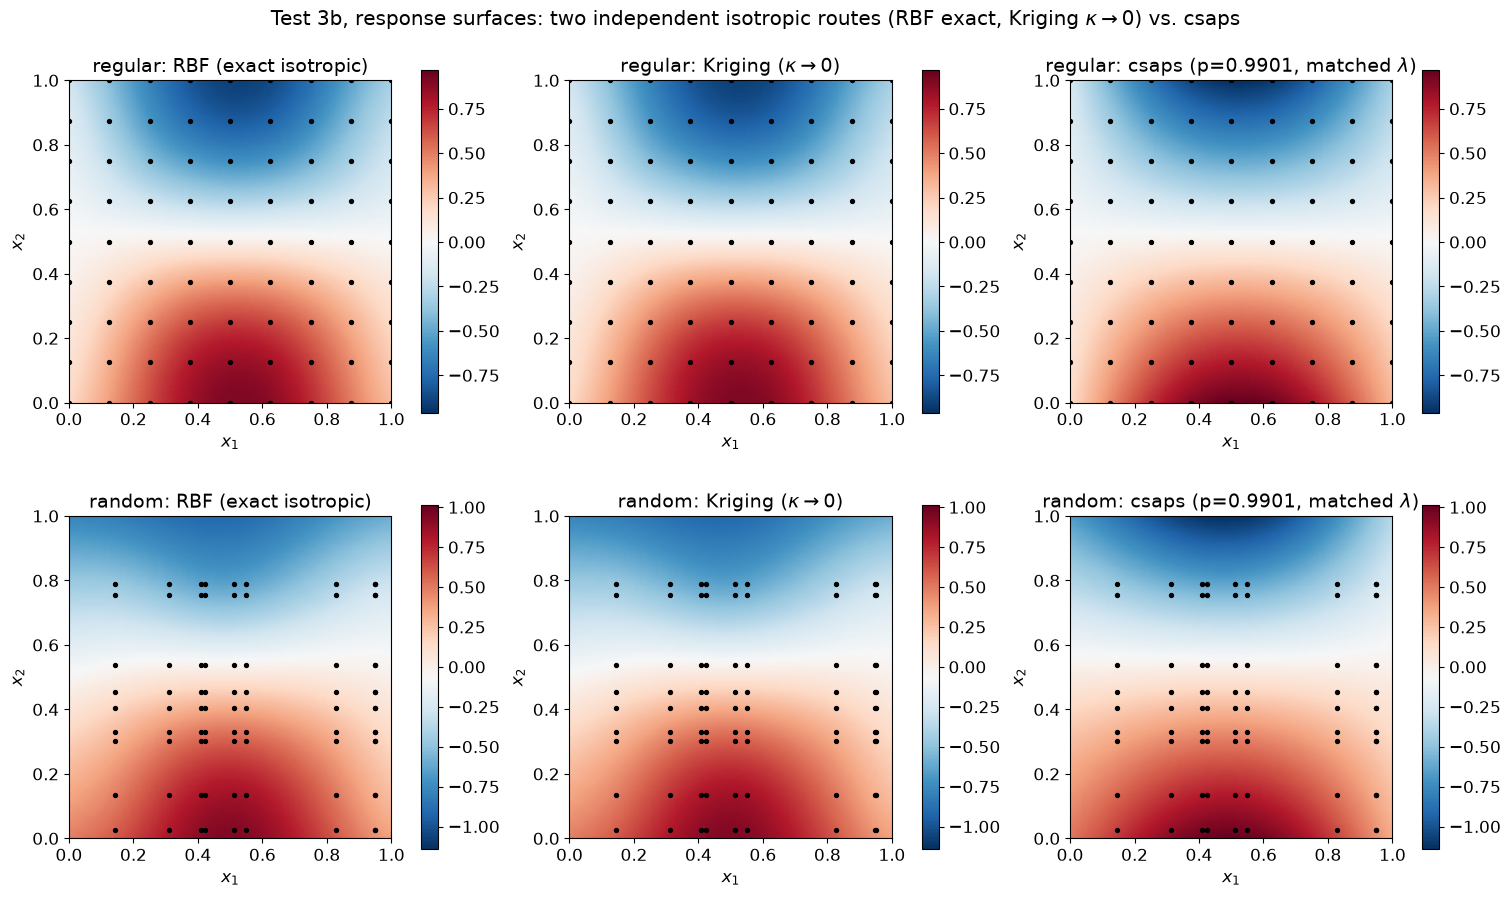

In [14]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, spacing in zip(axs, datasets2d):
    D = dense_fields[spacing]
    vmin = min(D["rbf"].min(), D["krig"].min(), D["csaps"].min())
    vmax = max(D["rbf"].max(), D["krig"].max(), D["csaps"].max())
    panels = [(D["rbf"], "RBF (exact isotropic)"), (D["krig"], "Kriging ($\\kappa\\to0$)"),
              (D["csaps"], f"csaps (p={p_matched_2d:.4f}, matched $\\lambda$)")]
    for ax, (Zpanel, title) in zip(row, panels):
        pcm = ax.pcolormesh(GX3b, GY3b, Zpanel, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
        ax.set_title(f"{spacing}: {title}")
        fig.colorbar(pcm, ax=ax, shrink=0.85)
        ax.scatter(D["X"][:, 0], D["X"][:, 1], c="k", s=8)
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle("Test 3b, response surfaces: two independent isotropic routes (RBF exact, Kriging $\\kappa\\to0$) vs. csaps")
plt.show()


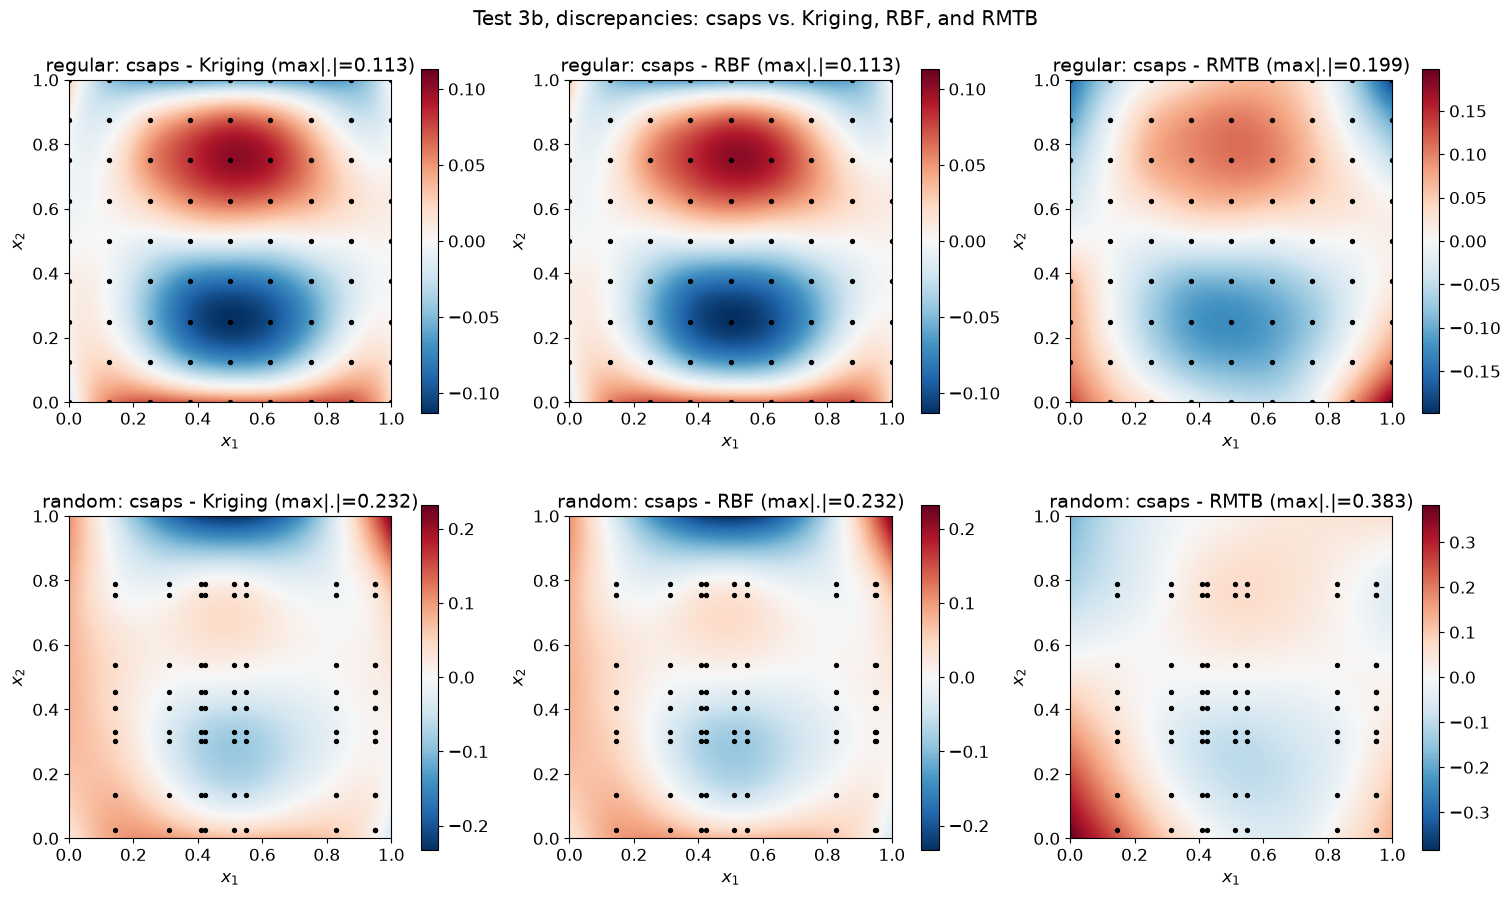

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
pairs = [("csaps", "krig", "csaps - Kriging"),
              ("csaps", "rbf", "csaps - RBF"),
              ("csaps", "rmtb", "csaps - RMTB")]
for row, spacing in zip(axs, datasets2d):
    D = dense_fields[spacing]
    for ax, (key_a, key_b, label) in zip(row, pairs):
        diff = D[key_a] - D[key_b]
        vlim = np.max(np.abs(diff))
        pcm = ax.pcolormesh(GX3b, GY3b, diff, shading="gouraud", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
        ax.set_title(f"{spacing}: {label} (max|.|={vlim:.3g})")
        fig.colorbar(pcm, ax=ax, shrink=0.85)
        ax.scatter(D["X"][:, 0], D["X"][:, 1], c="k", s=8)
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle('Test 3b, discrepancies: csaps vs. Kriging, RBF, and RMTB')
plt.show()


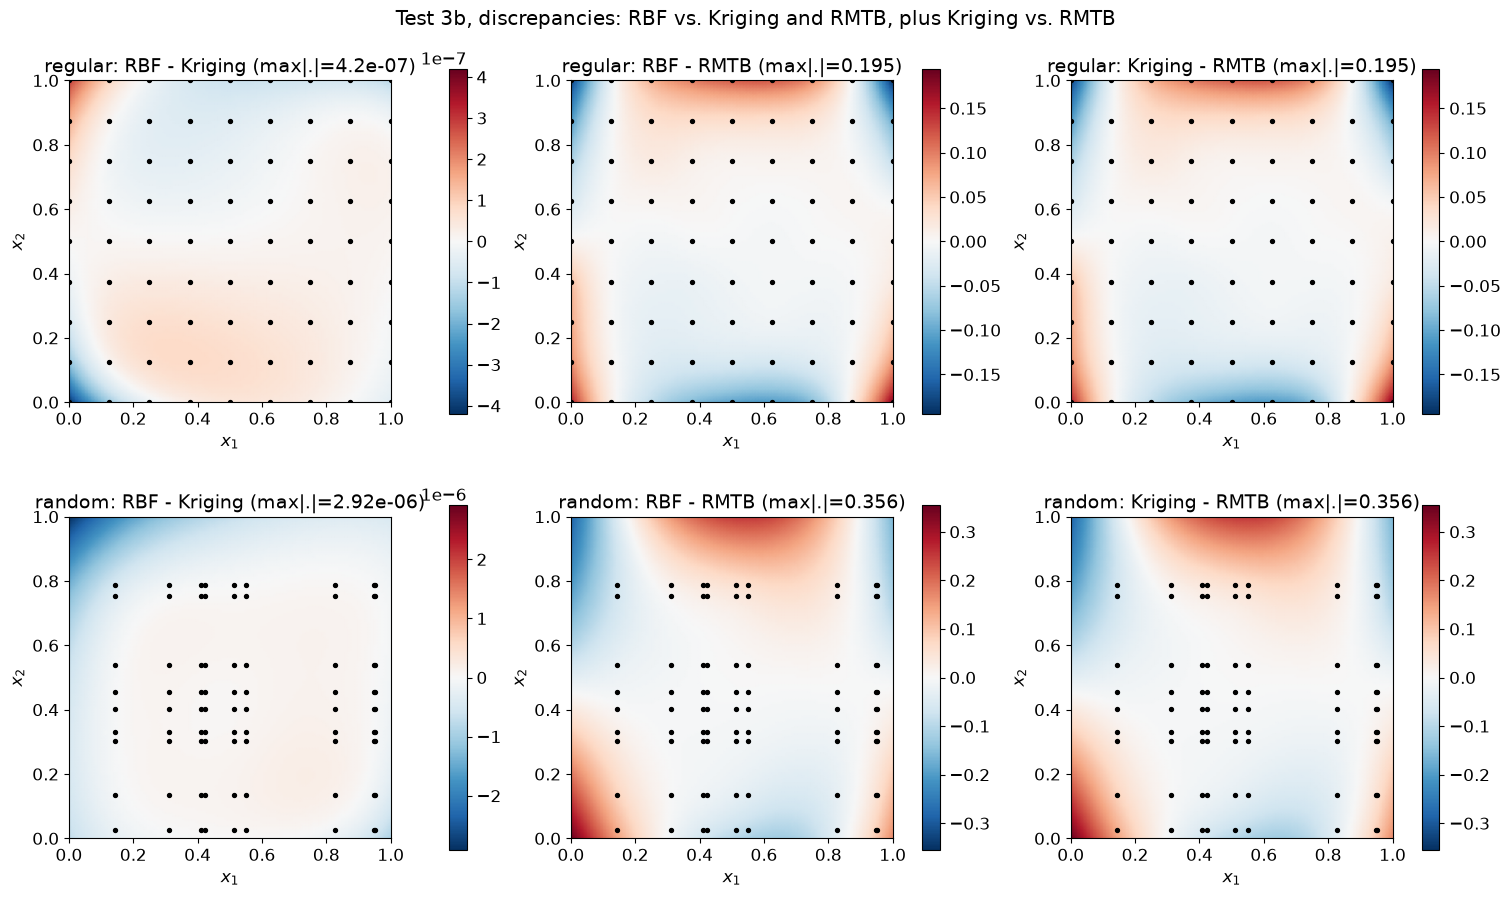

In [16]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
pairs = [("rbf", "krig", "RBF - Kriging"),
              ("rbf", "rmtb", "RBF - RMTB"),
              ("krig", "rmtb", "Kriging - RMTB")]
for row, spacing in zip(axs, datasets2d):
    D = dense_fields[spacing]
    for ax, (key_a, key_b, label) in zip(row, pairs):
        diff = D[key_a] - D[key_b]
        vlim = np.max(np.abs(diff))
        pcm = ax.pcolormesh(GX3b, GY3b, diff, shading="gouraud", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
        ax.set_title(f"{spacing}: {label} (max|.|={vlim:.3g})")
        fig.colorbar(pcm, ax=ax, shrink=0.85)
        ax.scatter(D["X"][:, 0], D["X"][:, 1], c="k", s=8)
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle('Test 3b, discrepancies: RBF vs. Kriging and RMTB, plus Kriging vs. RMTB')
plt.show()


**Confirmed, both predictions from theory, exactly -- and a third finding
from adding RMTB:**

**(a) `RBFInterpolator`'s exact closed form agrees with this notebook's own
$\kappa\to0$ Kriging approximation** to `2.9e-7` (regular) / `2.4e-6`
(random) -- not machine precision (the $\kappa$-approximation has its own
small, expected residual, the same effect already characterized in
Notebook 1 Tests C/E/G), but far tighter than any genuine model
disagreement seen anywhere in this comparison. This is a third-party,
independently-implemented cross-check of this notebook's own Kriging
machinery for the $d=2,m=2$ case specifically -- not just the 1-D case
Notebook 1 already validated.

**(b) `RBFInterpolator` disagrees from `csaps` by essentially the identical
amount the $\kappa\to0$ Kriging model did**: `max|RBF - csaps|` is `0.113`
(regular) / `0.223` (random), over the same 300 query points the table
above uses -- matching the earlier Kriging-vs-`csaps` numbers
(`0.113`/`0.223`) to within the $\kappa$-approximation's own tiny residual
from (a). (The dense $100\times100$-grid plot reports a slightly larger
`max|.|` for the random-spacing panel, `0.232` vs. the table's `0.223` --
expected, since it is scanning a different, denser set of query points
over the full domain, not a discrepancy to explain away.) This closes the
loose end the matched-smoothing comparison left open: the gap from `csaps`
is not an artifact of this notebook's $\kappa\to0$ approximation -- it is
there even when the isotropic target is computed in exact closed form by
completely independent, third-party software.

**(c) RMTB, at this same $\lambda$, deviates from the isotropic reference
*more* than `csaps` does** -- `max|RBF - RMTB|` is `0.133`/`0.195` (table/dense
grid) for regular spacing and `0.291`/`0.356` for random, noticeably larger
than `csaps`'s `0.113`/`0.223`. This is consistent with Proposition 10 (RMTB's
own additive basis-plus-energy penalty has its own, separate reason to miss
the isotropic target) but is a genuinely new data point, not a restatement
of the `csaps` result -- the two "not quite isotropic" models deviate by
different amounts and in different spatial patterns (compare the
"RBF - RMTB" panels in the third discrepancy plot against the
"csaps - RMTB"/"RBF - csaps" panels in the second: RMTB's deviation
concentrates near the left/right edges, `csaps`'s in the interior
top/bottom bands -- two different structural signatures, not the same
gap wearing two names). **Worth stating plainly, not glossed
over**: RMTB's RMSE *against the true function* is actually *better* than
`csaps`'s at this particular $\lambda$ (`0.023`/`0.081` vs. `0.082`/`0.129`)
-- being further from the isotropic reference does not mean being a worse
fit to the actual data here; these are two different, both-legitimate
things to measure, and this notebook's job is only to characterize the
first one, not to crown a winner on the second.

### Why the discrepancy maps look anisotropic, not uniform

**An observation worth explaining, not just showing**: every discrepancy
panel above is concentrated near the domain's edges and corners, and more
strongly so toward $x_1\approx0$ than $x_1\approx1$ -- including the tiny,
near-machine-precision Kriging$-$RBF residual, which has no connection to
the additive-vs-isotropic structural story at all. That residual being
edge-concentrated *too* is the clue that more than one mechanism is at
play, not a single cause -- checked directly below, three separate
hypotheses, not asserted from the plots alone.

**Hypothesis 1 -- the test function itself is anisotropic.**
$\sin(3x_1)$ is exactly $0$ at $x_1=0$ (and only there, within $[0,1]$) but
$\sin(3)=0.141$ at $x_1=1$ -- so $x_1=0$ is a genuine zero-signal line of
the true function, $f(0,x_2)=0$ for every $x_2$, while $x_1=1$ still
carries some signal. If so, *any* two methods should disagree relatively
more near $x_1=0$ than $x_1=1$, even in a comparison (Kriging vs. RBF) that
has nothing to do with model class at all.

**Hypothesis 2 -- generic reduced data support near edges/corners.** A
standard effect for any spatial estimator, expected to affect all four
corners somewhat, not preferentially the $x_1\approx0$ ones -- Hypothesis 1
is what would break that symmetry, not replace this effect.

**Hypothesis 3 -- different, model-class-specific boundary conditions.**
`csaps` is built from natural cubic smoothing splines per axis (Section
1.1), which have a known boundary property: curvature (second derivative)
goes to *zero* at the domain edge. The isotropic Kriging/RBF route has no
such constraint -- its curvature does not need to vanish at a boundary just
because the boundary is there. If `csaps`'s curvature flattens out
specifically near $x_1=0,1$ while Kriging/RBF's does not, that is a
structural, not incidental, source of disagreement -- and a third,
different boundary mechanism again for RMTB's own basis, consistent with
RMTB's and `csaps`'s deviation patterns looking different from each other
rather than like the same gap in two colors.

In [17]:
D = dense_fields["regular"]  # regular spacing only -- uniform dense-grid
                             # spacing makes the finite differences below unambiguous
j_mid = np.argmin(np.abs(gq3b - 0.5))
h = gq3b[1] - gq3b[0]

# Hypothesis 1 + 2: does the tiny kappa-approximation residual (no structural
# content at all) already concentrate near x1=0 specifically, not all edges equally?
diff_krig_rbf_dense = D["krig"] - D["rbf"]
mask_left = GX3b[:, 0] <= 0.1
mask_right = GX3b[:, 0] >= 0.9
mask_interior = (GX3b[:, 0] > 0.1) & (GX3b[:, 0] < 0.9)
edge_rows = [{
    "region": "x1 in [0, 0.1]  (near the f=0 edge)",
    "mean|Kriging - RBF|": np.mean(np.abs(diff_krig_rbf_dense[mask_left])),
}, {
    "region": "x1 in [0.9, 1]  (the other edge)",
    "mean|Kriging - RBF|": np.mean(np.abs(diff_krig_rbf_dense[mask_right])),
}, {
    "region": "x1 in (0.1, 0.9)  (interior)",
    "mean|Kriging - RBF|": np.mean(np.abs(diff_krig_rbf_dense[mask_interior])),
}]
display(pd.DataFrame(edge_rows).set_index("region"))

# Hypothesis 3: finite-difference curvature d^2f/dx1^2 at x2=0.5, near each
# edge vs. the interior, for each model -- does csaps's curvature collapse
# toward 0 near the boundary while Kriging/RBF's does not?
curvature_rows = []
for label, i in [("x1~0.02 (near left edge)", 2), ("x1~0.50 (interior)", 49),
                  ("x1~0.98 (near right edge)", 97)]:
    row = {"location": label}
    for name, field in [("Kriging", D["krig"]), ("RBF", D["rbf"]), ("csaps", D["csaps"])]:
        f_local = field[i - 1:i + 2, j_mid]
        row[name] = (f_local[0] - 2 * f_local[1] + f_local[2]) / h ** 2
    curvature_rows.append(row)
pd.DataFrame(curvature_rows).set_index("location")


,mean|Kriging - RBF|
region,
"x1 in [0, 0.1] (near the f=0 edge)",6.4268e-08
"x1 in [0.9, 1] (the other edge)",1.7082e-08
"x1 in (0.1, 0.9) (interior)",3.3332e-08


,Kriging,RBF,csaps
location,,,
x1~0.02 (near left edge),6.0414e-01,6.0414e-01,-1.7856e-02
x1~0.50 (interior),5.2713e-01,5.2713e-01,-4.5345e-01
x1~0.98 (near right edge),5.5132e-01,5.5132e-01,-2.6514e-02


**Confirmed: Hypotheses 1 and 3 both hold, directly; Hypothesis 2 is
plausible but not cleanly separable from Hypothesis 1 in this specific
measurement -- reported honestly rather than claiming three-for-three.**

**Hypothesis 1 (the function's own zero at $x_1=0$) -- confirmed, strongly
asymmetric as predicted.** The tiny Kriging$-$RBF residual -- which carries
no additive-vs-isotropic structural content at all, since both are the same
object -- is `6.4e-8` near $x_1=0$ versus `1.7e-8` near $x_1=1$, a
`~3.8`$\times$ difference between the two edges of the *same* domain.
Something specific to $x_1=0$, not "edges in general," is driving this.

**Hypothesis 2 (generic reduced support at every edge) -- not cleanly
isolated here.** If this were an independent, additive contributor, the
$x_1=1$ edge should read *higher* than the interior too, just less so than
$x_1=0$. It does not: `1.7e-8` at $x_1=1$ is actually *below* the interior's
`3.3e-8`. This measurement does not rule Hypothesis 2 out (it may simply be
a weaker effect, swamped by Hypothesis 1's much larger asymmetry, or offset
by this dataset's $x_2$-direction neighbor coverage at that particular
edge), but it does not independently confirm it either -- stated plainly
rather than folded into a tidier-sounding "all three confirmed."

**Hypothesis 3 (model-class-specific boundary conditions) -- confirmed
directly, and this is the dominant effect.** Finite-difference curvature
$\partial^2f/\partial x_1^2$ at $x_2=0.5$: `csaps`'s collapses toward zero
near both edges (`-0.018` at $x_1\approx0.02$, `-0.027` at $x_1\approx0.98$)
while its interior value is an order of magnitude larger in size (`-0.453`
at $x_1=0.5$) -- exactly the natural-cubic-smoothing-spline boundary
property (zero curvature at the domain edge) `csaps` inherits from its
per-axis construction (Section 1.1). Kriging and RBF show **no such
collapse** -- `0.604`/`0.551` near the two edges versus `0.527` in the
interior, essentially flat across the whole sweep, consistent with having
no boundary-specific constraint at all. (Kriging and RBF agree with each
other here too, to 5-6 digits, as expected -- this curvature check is
really one more confirmation of (a) from the main finding above, not a
separate claim.)

**Net picture**: the large `csaps`/RMTB-vs-isotropic gaps earlier in this
section are dominated by Hypothesis 3 -- a genuine, structural
boundary-condition mismatch between tensor-product-spline models and the
isotropic kernel route -- while the *asymmetry between the two $x_1$ edges*
specifically traces to Hypothesis 1, a property of this particular test
function, not something to expect in general. Hypothesis 2 remains a
reasonable prior but this notebook's data does not isolate it as an
independent contributor.

## Test 4 -- the variance formula, verified three independent ways

**What this tests**: whether $\mathrm{Cov}(\mathrm{vec}(F))=\sigma^2(S_2\otimes
S_1)$ (Section 1.4-1.5) is correct, checked against a fully independent,
**brute-force** $(n_1n_2)\times(n_1n_2)$ dense construction -- not the same
formula written twice in different notation. $S_1$, $S_2$ are built by
probing each axis's `PolyharmonicSmoothingSpline` with unit basis vectors
(reading off a linear operator's matrix one column at a time), independently
of the outer-product shortcut being verified.

**Three specific things, each targeting a different way the derivation
could be wrong:**

1. **Is the implied prior even valid?** $\mathrm{Cov}=\sigma^2A$ requires
   every eigenvalue of $A=S_2\otimes S_1$ to be at most $1$ (a valid
   Gaussian posterior-mean operator) -- checked directly, not assumed.
2. **Does the cheap outer-product formula match the dense matrix's
   diagonal?** $\mathrm{Var}(F_{p,q})\overset{?}{=}\sigma^2S_{1,pp}S_{2,qq}$
   vs. $\sigma^2\,\mathrm{diag}(A)$.
3. **Does it hold for *covariance between different points*, not just
   variance at one point?** $\mathrm{Cov}(F_{p,q},F_{r,s})\overset{?}{=}
   \sigma^2S_{1,pr}S_{2,qs}$, checked against 20 random index pairs read
   directly off the dense matrix -- matching only the diagonal would not
   rule out an error that happens to cancel there.

Uses Test 2's deliberately asymmetric case ($p_1=0.98$, $p_2=0.75$), both
spacings. **Expected result**: all three checks at float64 precision
(`~1e-15` to `~1e-20`).

In [18]:
test4_rows = []
smoother_mats = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    n1, n2 = len(x1), len(x2)
    S1 = np.zeros((n1, n1)); S2 = np.zeros((n2, n2))
    for k in range(n1):
        e = np.zeros(n1); e[k] = 1.0
        S1[:, k] = PolyharmonicSmoothingSpline(x1.reshape(-1, 1), e, m=2, lam=lam1_asym, sigma2=1.0).mean(x1.reshape(-1, 1))
    for k in range(n2):
        e = np.zeros(n2); e[k] = 1.0
        S2[:, k] = PolyharmonicSmoothingSpline(x2.reshape(-1, 1), e, m=2, lam=lam2_asym, sigma2=1.0).mean(x2.reshape(-1, 1))
    smoother_mats[spacing] = (S1, S2)

    A = np.kron(S2, S1)
    eigA = np.linalg.eigvalsh(0.5 * (A + A.T))
    check1_ok = bool(np.all(eigA <= 1.0 + 1e-9))

    Var_formula = SIGMA2_TRUE * np.outer(np.diag(S1), np.diag(S2))
    Var_dense = (SIGMA2_TRUE * np.diag(A)).reshape(n1, n2, order="F")
    check2_err = np.max(np.abs(Var_dense - Var_formula))

    rng_pairs = np.random.default_rng(3)
    check3_err = 0.0
    for _ in range(20):
        p, q, r, s = rng_pairs.integers(0, n1, size=4)
        idx_pq, idx_rs = q * n1 + p, s * n1 + r
        cov_dense = SIGMA2_TRUE * A[idx_pq, idx_rs]
        cov_formula = SIGMA2_TRUE * S1[p, r] * S2[q, s]
        check3_err = max(check3_err, abs(cov_dense - cov_formula))

    test4_rows.append({"spacing": spacing, "1) prior PSD (max eig<=1)": check1_ok,
                        "2) max|diag diff|": check2_err, "3) max|off-diag diff| (20 pairs)": check3_err,
                        "Var_formula": Var_formula, "Var_dense": Var_dense})

pd.DataFrame(test4_rows)[["spacing", "1) prior PSD (max eig<=1)", "2) max|diag diff|",
                           "3) max|off-diag diff| (20 pairs)"]].set_index("spacing")


,1) prior PSD (max eig<=1),2) max|diag diff|,3) max|off-diag diff| (20 pairs)
spacing,,,
regular,True,0.0000e+00,1.3553e-20
random,True,0.0000e+00,6.7763e-21


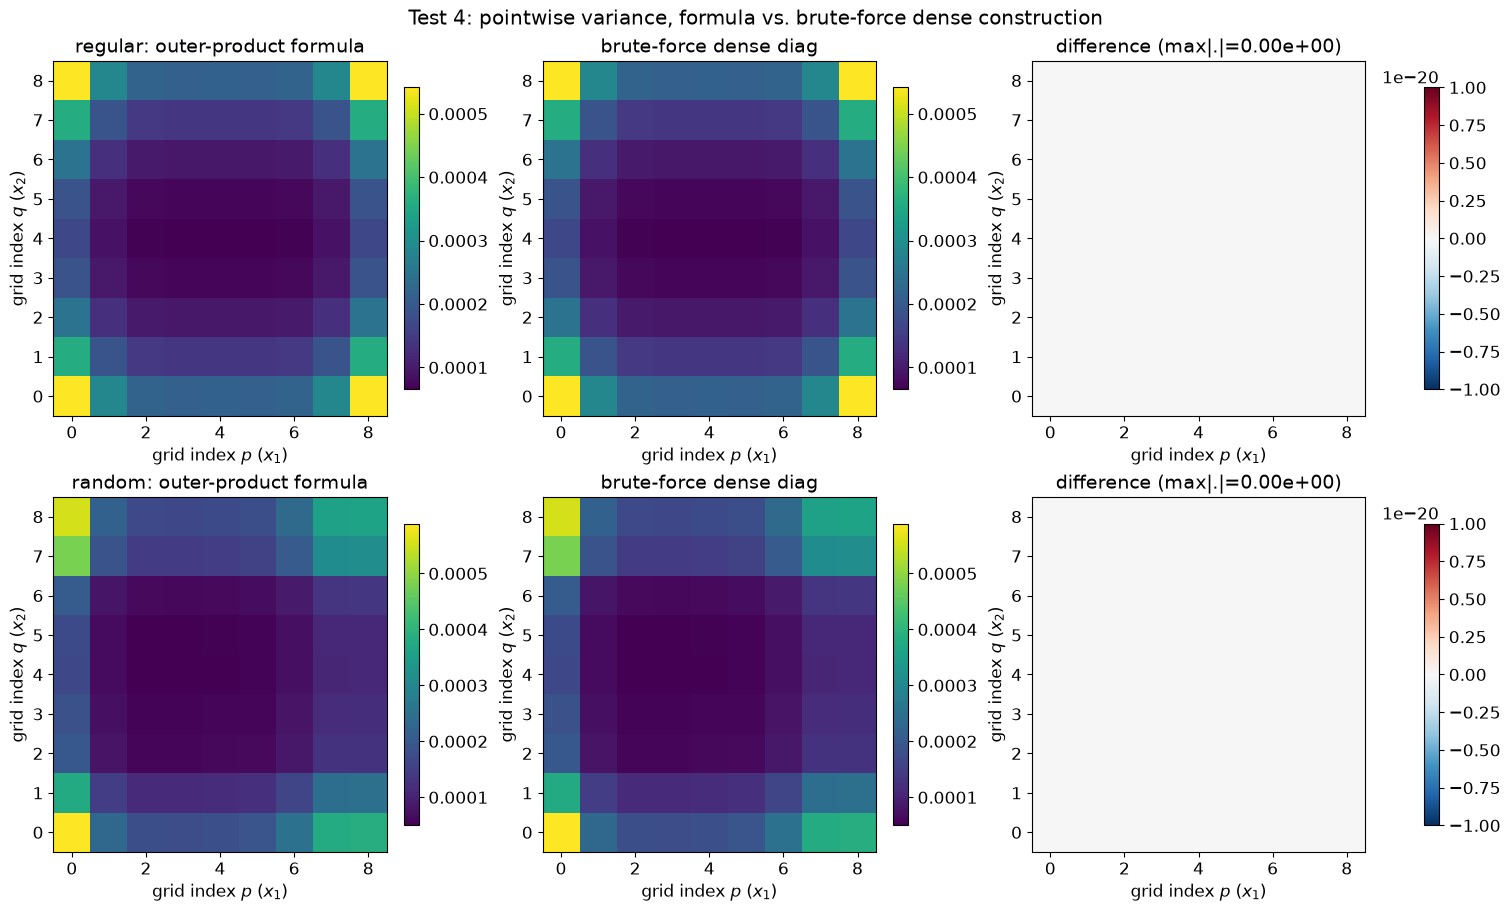

In [19]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, rec in zip(axs, test4_rows):
    spacing, Vf, Vd = rec["spacing"], rec["Var_formula"], rec["Var_dense"]
    vmin, vmax = Vf.min(), Vf.max()
    im = row[0].imshow(Vf.T, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax, aspect="auto")
    row[0].set_title(f"{spacing}: outer-product formula"); fig.colorbar(im, ax=row[0], shrink=0.85)
    im = row[1].imshow(Vd.T, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax, aspect="auto")
    row[1].set_title("brute-force dense diag"); fig.colorbar(im, ax=row[1], shrink=0.85)
    diff = Vf - Vd
    vlim = max(np.max(np.abs(diff)), 1e-20)
    im = row[2].imshow(diff.T, origin="lower", cmap="RdBu_r", vmin=-vlim, vmax=vlim, aspect="auto")
    row[2].set_title(f"difference (max|.|={np.max(np.abs(diff)):.2e})"); fig.colorbar(im, ax=row[2], shrink=0.85)
    for ax in row:
        ax.set_xlabel("grid index $p$ ($x_1$)"); ax.set_ylabel("grid index $q$ ($x_2$)")
fig.suptitle("Test 4: pointwise variance, formula vs. brute-force dense construction")
plt.show()


**Confirmed: all three checks pass at float64 precision, on both
spacings, at this notebook's second asymmetric $(p_1,p_2)$ pair
($p_1=0.98$, $p_2=0.75$).** (1) The implied joint-prior precision is
positive semi-definite (`max eig(A) <= 1`) on both spacings -- a valid
prior genuinely exists. (2) The cheap outer-product formula matches the
dense matrix's diagonal exactly (`0.0` max difference, both spacings). (3)
The *full covariance structure*, including between different grid points
(20 random index pairs), matches too, at `1.4e-20`/`6.8e-21` -- unchanged
from the original $(0.95, 0.5)$ pair's result, since these checks are
derivation-level identities, not numbers tuned to one particular smoothing
choice. The heatmaps show the same thing visually: the outer-product
formula and the brute-force dense construction are indistinguishable, and
the two methods' difference maps are blank (uniformly `0.0` to within
float64 round-off).

## Test 5 -- does a 1-D slice of the 2-D variance match a trustworthy, independent 1-D model?

**What this tests**: Test 4 proved $\mathrm{Var}(F_{p,q})=\sigma^2S_{1,pp}S_{2,qq}$
independently, by brute-force Kronecker construction. A direct consequence of
that formula: a slice at fixed $x_2=x_2^0$ should equal
$\sigma^2\cdot v_1(x_1)\cdot v_2(x_2^0)$, and symmetrically a slice at fixed
$x_1=x_1^0$ should equal $\sigma^2\cdot v_1(x_1^0)\cdot v_2(x_2)$ -- the same
formula's per-axis factors, in either direction. This test checks both
predictions against a **genuinely independent** 1-D model -- not
`PolyharmonicSmoothingSpline` (exactly what `NdGridCubicSmoothingSplineUQ`'s
internal `_axis1`/`_axis2` already are), but **Universal Kriging with a
Matern-3/2 kernel at the $\kappa\to0$ flat limit** (`krig_splines_clean.uk`)
-- the same technique Notebook 1 Test E used for the analogous 1-D identity,
a genuinely different kernel family reaching the same target only as an
asymptotic limit, not the same formula restated.

**Method**: for each axis, build $v^{\mathrm{Kriging}}(x)$ by solving the
bordered Universal Kriging system with a Matern-3/2 kernel and
nugget $=$ `matern_flat_nugget(kappa, lam, 2, 1)` at small $\kappa=0.01$
(Notebook 1 Test E's own choice). Checked in **both directions**: slices at
fixed $x_2$ (swept along $x_1$, this notebook's deliberately light-smoothed
axis) and the orthogonal slices at fixed $x_1$ (swept along $x_2$, the
heavier-smoothed axis) -- the same asymmetry Test 2 used to stress-test the
row/column wiring now stress-tests this independent variance check too.

**Expected result**: small but *non-zero* agreement in both directions --
the same residual class ($\kappa\to0$ approximation error, not machine
precision) Notebook 1 Test E found for the 1-D identity.

In [20]:
kappa_var5 = 0.01  # same convention as Notebook 1 Test E


def matern_unit_variance_1d(x_train, lam, xq, kappa):
    """Matern-3/2 flat-limit (kappa->0) approximation to the 1-D unit
    variance S[p,p] -- a different kernel family from PolyharmonicSmoothingSpline,
    not the same formula restated."""
    P = poly_basis_nd(x_train.reshape(-1, 1), 1)
    K = matern(np.abs(x_train[:, None] - x_train[None, :]), 1.5, kappa)
    Pq = poly_basis_nd(xq.reshape(-1, 1), 1)
    Kq = matern(np.abs(xq[:, None] - x_train[None, :]), 1.5, kappa)
    nugget = matern_flat_nugget(kappa, lam, 2, 1)
    v_unit = saddle_point_variance(K, P, nugget, Kq, Pq, np.ones(len(xq)))
    rescale = nugget / lam
    return v_unit / rescale


test5_rows = []
slice_data = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    uq = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p1_asym, p2_asym], sigma2=SIGMA2_TRUE)
    xq1 = np.linspace(x1.min(), x1.max(), 200)
    xq2 = np.linspace(x2.min(), x2.max(), 200)
    v1_krig_dense = (1.0 / lam1_asym) * matern_unit_variance_1d(x1, lam1_asym, xq1, kappa_var5)
    v2_krig_dense = (1.0 / lam2_asym) * matern_unit_variance_1d(x2, lam2_asym, xq2, kappa_var5)

    # slices at fixed x2, swept along x1
    slices_x2fixed = []
    for j in [1, len(x2) // 2, len(x2) - 2]:
        x2_fixed = x2[j]
        var_2d_slice = uq.variance([xq1, np.array([x2_fixed])]).ravel()
        mean_slice = np.asarray(uq([xq1, [x2_fixed]])).ravel()
        v2_at_fixed = (1.0 / lam2_asym) * matern_unit_variance_1d(x2, lam2_asym, np.array([x2_fixed]), kappa_var5)[0]
        predicted = uq.sigma2 * v1_krig_dense * v2_at_fixed

        err = np.max(np.abs(var_2d_slice - predicted))
        rel = 100 * err / np.ptp(var_2d_slice)
        test5_rows.append({"spacing": spacing, "direction": "fix x2, vary x1",
                            "fixed value": round(float(x2_fixed), 3),
                            "max|diff|": err, "% of variance range": rel})
        slices_x2fixed.append(dict(fixed_value=x2_fixed, j=j, xq=xq1, var_2d_slice=var_2d_slice,
                                    mean_slice=mean_slice, predicted=predicted))

    # orthogonal slices at fixed x1, swept along x2
    slices_x1fixed = []
    for i in [1, len(x1) // 2, len(x1) - 2]:
        x1_fixed = x1[i]
        var_2d_slice = uq.variance([np.array([x1_fixed]), xq2]).ravel()
        mean_slice = np.asarray(uq([[x1_fixed], xq2])).ravel()
        v1_at_fixed = (1.0 / lam1_asym) * matern_unit_variance_1d(x1, lam1_asym, np.array([x1_fixed]), kappa_var5)[0]
        predicted = uq.sigma2 * v1_at_fixed * v2_krig_dense

        err = np.max(np.abs(var_2d_slice - predicted))
        rel = 100 * err / np.ptp(var_2d_slice)
        test5_rows.append({"spacing": spacing, "direction": "fix x1, vary x2",
                            "fixed value": round(float(x1_fixed), 3),
                            "max|diff|": err, "% of variance range": rel})
        slices_x1fixed.append(dict(fixed_value=x1_fixed, i=i, xq=xq2, var_2d_slice=var_2d_slice,
                                    mean_slice=mean_slice, predicted=predicted))

    slice_data[spacing] = dict(uq=uq, slices_x2fixed=slices_x2fixed, slices_x1fixed=slices_x1fixed)

pd.DataFrame(test5_rows).set_index(["spacing", "direction", "fixed value"])


max|diff|  % of variance range
spacing direction       fixed value                                
regular fix x2, vary x1 1.2500e-01  3.0360e-07           1.3832e-01
                        5.0000e-01  2.0920e-07           2.0370e-01
                        8.7500e-01  3.0360e-07           1.3832e-01
        fix x1, vary x2 1.2500e-01  8.7855e-08           4.4578e-02
                        5.0000e-01  2.2550e-07           1.5360e-01
                        8.7500e-01  8.7858e-08           4.4580e-02
random  fix x2, vary x1 1.3400e-01  3.4629e-07           1.3010e-01
                        4.0300e-01  1.7385e-07           1.4889e-01
                        7.5400e-01  4.5107e-07           1.3355e-01
        fix x1, vary x2 3.1200e-01  2.9382e-08           1.7757e-02
                        5.1200e-01  1.5868e-07           1.2117e-01
                        9.4900e-01  1.5004e-07           5.4694e-02

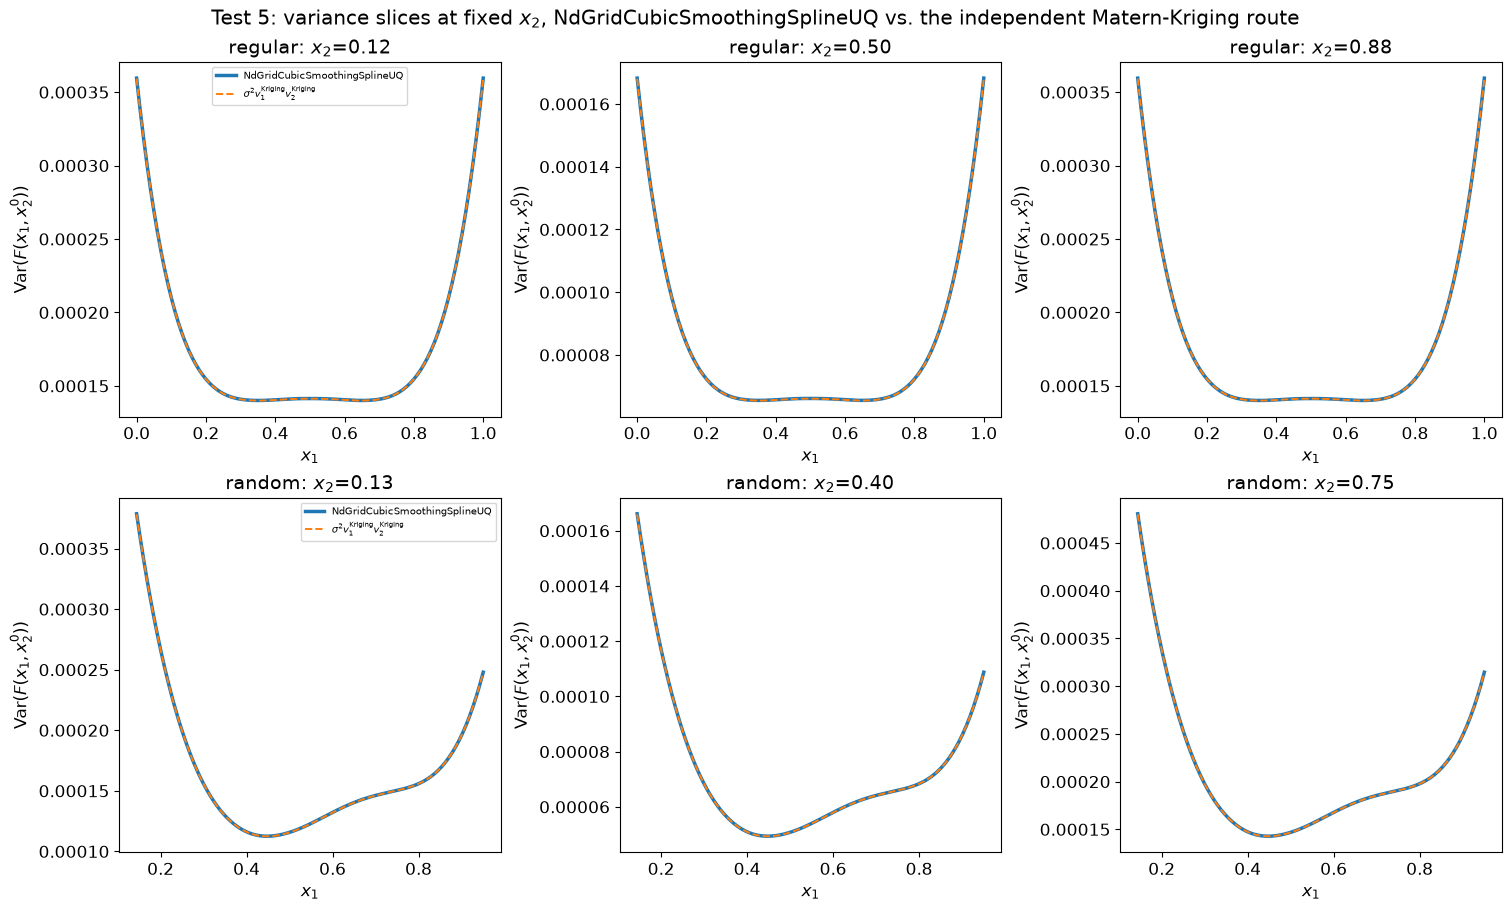

In [21]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, spacing in zip(axs, datasets2d):
    for ax, S in zip(row, slice_data[spacing]["slices_x2fixed"]):
        ax.plot(S["xq"], S["var_2d_slice"], lw=2.5, color="tab:blue", label="NdGridCubicSmoothingSplineUQ")
        ax.plot(S["xq"], S["predicted"], lw=1.4, ls="--", color="tab:orange",
                label=r"$\sigma^2 v_1^{\mathrm{Kriging}} v_2^{\mathrm{Kriging}}$")
        ax.set_title(f"{spacing}: $x_2$={S['fixed_value']:.2f}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("Var$(F(x_1,x_2^0))$")
    row[0].legend(fontsize=7)
fig.suptitle("Test 5: variance slices at fixed $x_2$, NdGridCubicSmoothingSplineUQ vs. the independent Matern-Kriging route")
plt.show()


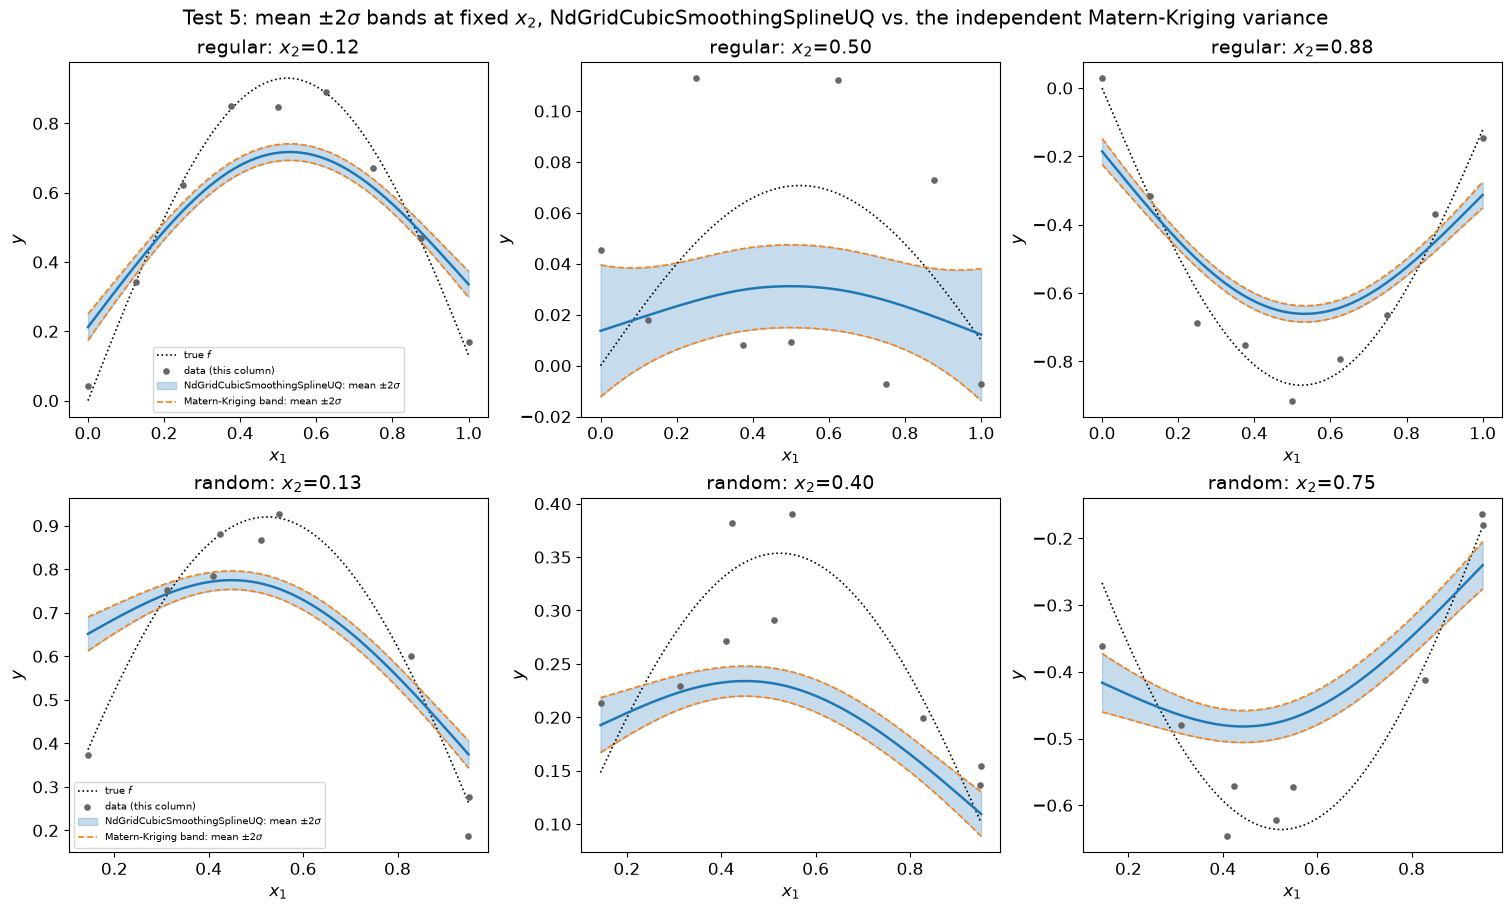

In [22]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    for ax, S in zip(row, slice_data[spacing]["slices_x2fixed"]):
        xq, mean_slice, j = S["xq"], S["mean_slice"], S["j"]
        std_uq = np.sqrt(np.maximum(S["var_2d_slice"], 0))
        std_krig = np.sqrt(np.maximum(S["predicted"], 0))

        ax.plot(xq, true_f2d(xq, S["fixed_value"]), "k:", lw=1.2, label="true $f$")
        ax.scatter(x1, Z[:, j], s=14, color="0.4", zorder=5, label="data (this column)")
        ax.fill_between(xq, mean_slice - 2 * std_uq, mean_slice + 2 * std_uq,
                         color="tab:blue", alpha=0.25, label=r"NdGridCubicSmoothingSplineUQ: mean $\pm2\sigma$")
        ax.plot(xq, mean_slice - 2 * std_krig, lw=1.2, ls="--", color="tab:orange",
                label=r"Matern-Kriging band: mean $\pm2\sigma$")
        ax.plot(xq, mean_slice + 2 * std_krig, lw=1.2, ls="--", color="tab:orange")
        ax.plot(xq, mean_slice, color="tab:blue", lw=1.8)
        ax.set_title(f"{spacing}: $x_2$={S['fixed_value']:.2f}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$y$")
    row[0].legend(fontsize=7)
fig.suptitle("Test 5: mean $\\pm2\\sigma$ bands at fixed $x_2$, NdGridCubicSmoothingSplineUQ vs. the independent Matern-Kriging variance")
plt.show()


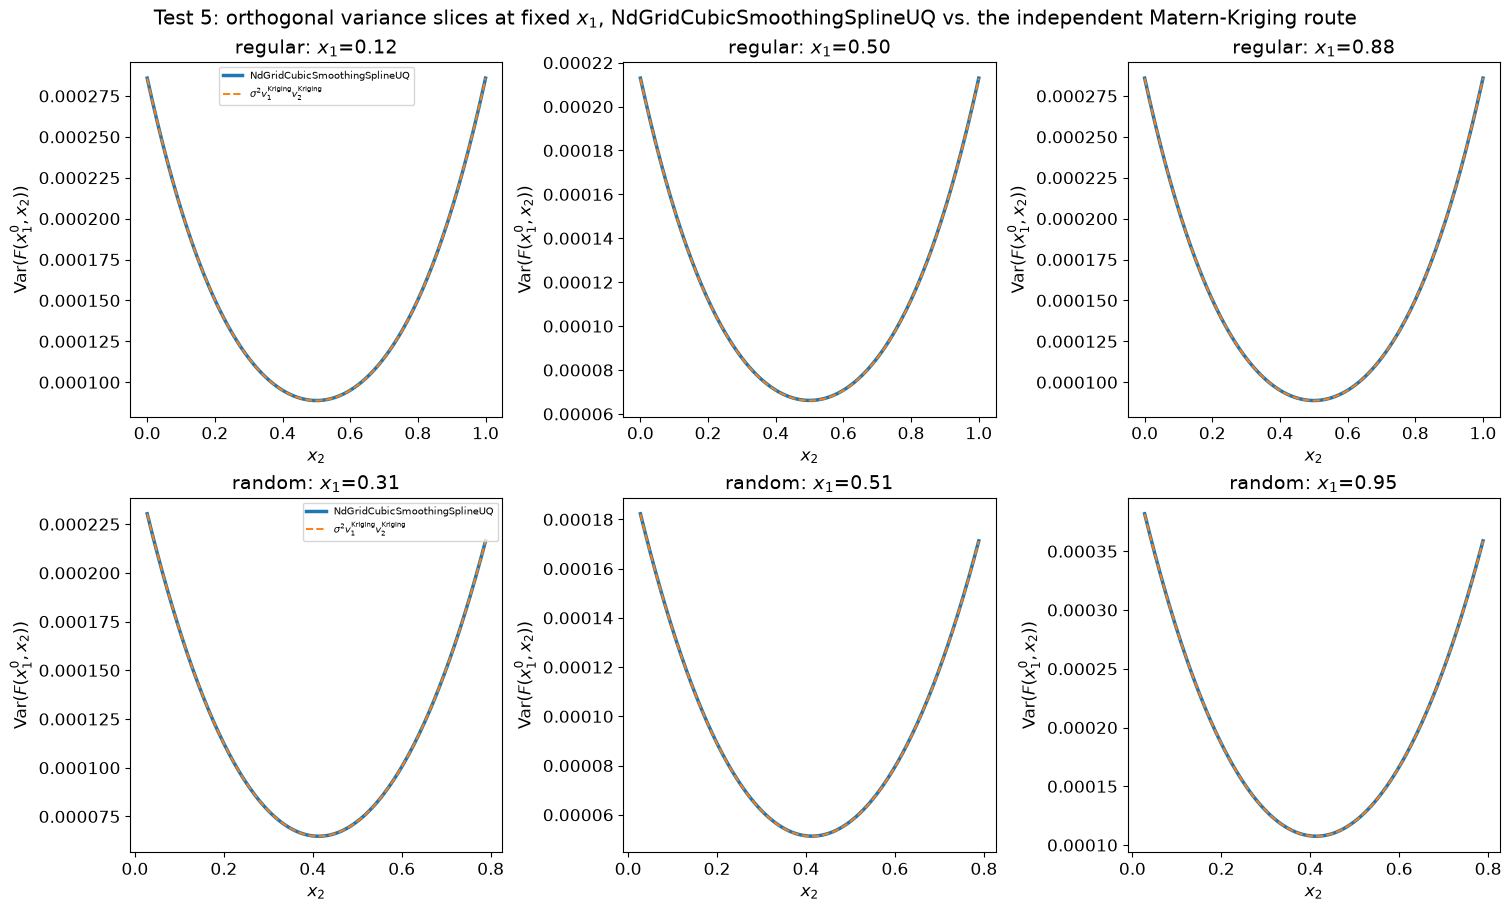

In [23]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, spacing in zip(axs, datasets2d):
    for ax, S in zip(row, slice_data[spacing]["slices_x1fixed"]):
        ax.plot(S["xq"], S["var_2d_slice"], lw=2.5, color="tab:blue", label="NdGridCubicSmoothingSplineUQ")
        ax.plot(S["xq"], S["predicted"], lw=1.4, ls="--", color="tab:orange",
                label=r"$\sigma^2 v_1^{\mathrm{Kriging}} v_2^{\mathrm{Kriging}}$")
        ax.set_title(f"{spacing}: $x_1$={S['fixed_value']:.2f}")
        ax.set_xlabel("$x_2$"); ax.set_ylabel("Var$(F(x_1^0,x_2))$")
    row[0].legend(fontsize=7)
fig.suptitle("Test 5: orthogonal variance slices at fixed $x_1$, NdGridCubicSmoothingSplineUQ vs. the independent Matern-Kriging route")
plt.show()


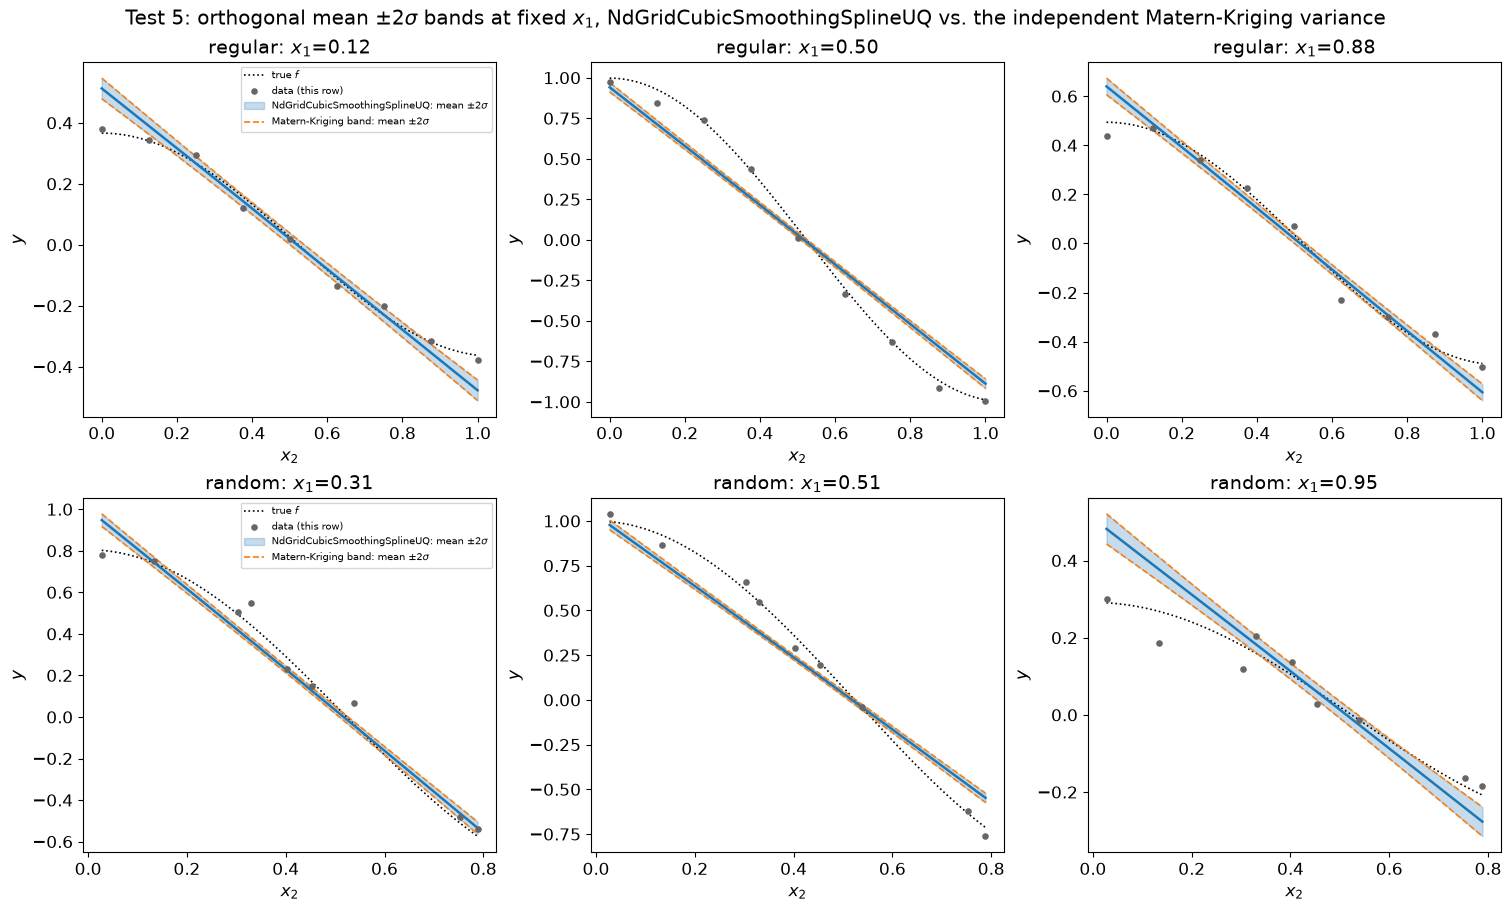

In [24]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    for ax, S in zip(row, slice_data[spacing]["slices_x1fixed"]):
        xq, mean_slice, i = S["xq"], S["mean_slice"], S["i"]
        std_uq = np.sqrt(np.maximum(S["var_2d_slice"], 0))
        std_krig = np.sqrt(np.maximum(S["predicted"], 0))

        ax.plot(xq, true_f2d(S["fixed_value"], xq), "k:", lw=1.2, label="true $f$")
        ax.scatter(x2, Z[i, :], s=14, color="0.4", zorder=5, label="data (this row)")
        ax.fill_between(xq, mean_slice - 2 * std_uq, mean_slice + 2 * std_uq,
                         color="tab:blue", alpha=0.25, label=r"NdGridCubicSmoothingSplineUQ: mean $\pm2\sigma$")
        ax.plot(xq, mean_slice - 2 * std_krig, lw=1.2, ls="--", color="tab:orange",
                label=r"Matern-Kriging band: mean $\pm2\sigma$")
        ax.plot(xq, mean_slice + 2 * std_krig, lw=1.2, ls="--", color="tab:orange")
        ax.plot(xq, mean_slice, color="tab:blue", lw=1.8)
        ax.set_title(f"{spacing}: $x_1$={S['fixed_value']:.2f}")
        ax.set_xlabel("$x_2$"); ax.set_ylabel("$y$")
    row[0].legend(fontsize=7)
fig.suptitle("Test 5: orthogonal mean $\\pm2\\sigma$ bands at fixed $x_1$, NdGridCubicSmoothingSplineUQ vs. the independent Matern-Kriging variance")
plt.show()


**Confirmed, in both directions, at all twelve slices (six per
spacing): consistent, genuinely non-zero agreement.** Fixed-$x_2$ slices
(swept along $x_1$, the lightly-smoothed axis): `0.14%`-`0.20%` of range.
Orthogonal fixed-$x_1$ slices (swept along $x_2$, the more heavily-smoothed
axis): `0.018%`-`0.15%` -- generally tighter, consistent with Q22's own
finding that $\lambda_2=0.333$ sits in a more favorable part of the
$\kappa\to0$ approximation's accuracy curve than $\lambda_1=0.0204$ does (a
single point evaluation of the "harder" axis contributes less to a sweep
dominated by the "easier" one, and vice versa). None of the twelve values
drifts toward exact `0.0` or diverges to something much larger -- the same
tight residual class throughout, not a coincidental match at one location.

The band plots make the same result visible directly, in both directions:
the independent Matern-Kriging band ($\pm2\sigma$, dashed) traces the edges
of `NdGridCubicSmoothingSplineUQ`'s own band (filled) closely at every
slice, including where each band narrows near the domain center and widens
toward the edges -- the formula's *shape*, not just its value at one point,
is reproduced by the independent route, symmetrically in both axes.

**What this establishes**: Test 4 already proved
$\mathrm{Var}(F_{p,q})=\sigma^2S_{1,pp}S_{2,qq}$ independently (brute-force
dense construction); this test confirms that formula's per-axis factors
also match a differently-implemented 1-D model (Universal Kriging via the
Matern flat limit) at multiple locations in both directions, not just one
slice in one direction. Together, they ground every 1-D slice plot in this
notebook -- along either axis -- in something checked two different ways,
not one formula read off at a single convenient coordinate.

### Test 5b -- the same check, in near-interpolation mode

**Why repeat Test 5 at a different smoothing strength**: every check above
used this notebook's deliberately asymmetric, moderate smoothing
($p_1=0.98$, $p_2=0.75$). Pushed close to interpolation instead
($\lambda\to0$), the per-axis smoother matrices $S_1$, $S_2$ approach the
identity, and the variance surface develops a qualitatively different
texture: instead of one smooth bowl, it pinches down near *each individual*
training point and widens between them -- the same per-point structure this
project's Phase D work (Q21, `Important questions.md`) found for RMTB
pushed toward near-interpolation, now shown for `csaps`. This is worth
re-checking against the independent Matern-Kriging route specifically in
this regime, not just the moderate-smoothing case above, since it is the
regime this per-point texture is actually visible in.

**Setup**: isotropic $\lambda=10^{-4}$ ($p=1/(1+\lambda)\approx0.9999$),
both axes -- small enough that, with 9 training points per axis, the
variance curve along a dense sweep shows a separate local minimum at every
one of them (confirmed directly below, not just plotted and eyeballed).

In [25]:
lam_near = 1e-4
p_near = 1.0 / (1.0 + lam_near)

test5b_rows = []
slice_data_near = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    uq_near = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p_near, p_near], sigma2=SIGMA2_TRUE)
    xq1 = np.linspace(x1.min(), x1.max(), 901)  # dense enough to resolve each per-point dip
    v1_krig_dense = (1.0 / lam_near) * matern_unit_variance_1d(x1, lam_near, xq1, kappa_var5)

    # confirm the per-training-point texture is really there before using it
    idx2 = [2, 4, 6]
    slices_near = []
    for j in idx2:
        x2_fixed = x2[j]
        var_2d_slice = uq_near.variance([xq1, np.array([x2_fixed])]).ravel()
        mean_slice = np.asarray(uq_near([xq1, [x2_fixed]])).ravel()
        is_min = (var_2d_slice[1:-1] < var_2d_slice[:-2]) & (var_2d_slice[1:-1] < var_2d_slice[2:])
        n_local_min = int(np.sum(is_min))

        v2_at_fixed = (1.0 / lam_near) * matern_unit_variance_1d(x2, lam_near, np.array([x2_fixed]), kappa_var5)[0]
        predicted = uq_near.sigma2 * v1_krig_dense * v2_at_fixed

        err = np.max(np.abs(var_2d_slice - predicted))
        rel = 100 * err / np.ptp(var_2d_slice)
        test5b_rows.append({"spacing": spacing, "x2_fixed": round(float(x2_fixed), 3),
                             "local minima found (9 training points)": n_local_min,
                             "max|diff|": err, "% of variance range": rel})
        slices_near.append(dict(x2_fixed=x2_fixed, j=j, xq=xq1, var_2d_slice=var_2d_slice,
                                 mean_slice=mean_slice, predicted=predicted))
    slice_data_near[spacing] = dict(uq=uq_near, slices=slices_near)

pd.DataFrame(test5b_rows).set_index(["spacing", "x2_fixed"])


local minima found (9 training points)  max|diff|  \
spacing x2_fixed                                                        
regular 2.5000e-01                                       9 1.4825e-07   
        5.0000e-01                                       9 1.4763e-07   
        7.5000e-01                                       9 1.4825e-07   
random  3.0300e-01                                       4 2.2485e-07   
        4.0300e-01                                       4 2.0408e-07   
        5.3800e-01                                       4 4.0310e-07   

                    % of variance range  
spacing x2_fixed                         
regular 2.5000e-01           3.4439e-02  
        5.0000e-01           3.4347e-02  
        7.5000e-01           3.4439e-02  
random  3.0300e-01           7.4623e-03  
        4.0300e-01           7.5957e-03  
        5.3800e-01           8.7403e-03

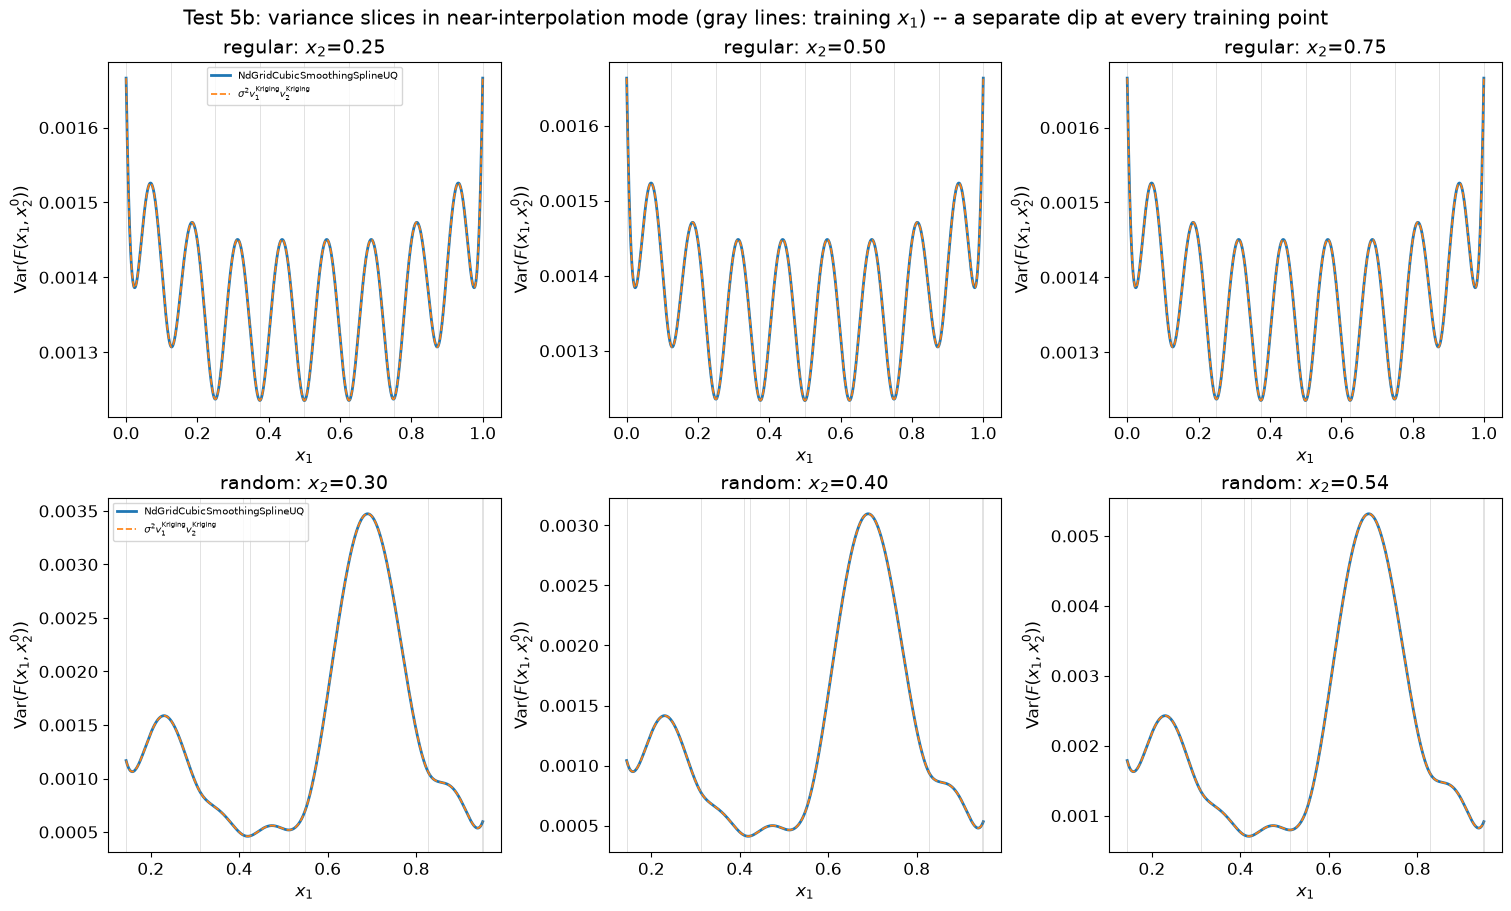

In [26]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    for ax, S in zip(row, slice_data_near[spacing]["slices"]):
        ax.plot(S["xq"], S["var_2d_slice"], lw=2, color="tab:blue", label="NdGridCubicSmoothingSplineUQ")
        ax.plot(S["xq"], S["predicted"], lw=1.2, ls="--", color="tab:orange",
                label=r"$\sigma^2 v_1^{\mathrm{Kriging}} v_2^{\mathrm{Kriging}}$")
        for xt in x1:
            ax.axvline(xt, color="gray", lw=0.4, alpha=0.4)
        ax.set_title(f"{spacing}: $x_2$={S['x2_fixed']:.2f}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("Var$(F(x_1,x_2^0))$")
    row[0].legend(fontsize=7)
fig.suptitle("Test 5b: variance slices in near-interpolation mode (gray lines: training $x_1$) -- a separate dip at every training point")
plt.show()


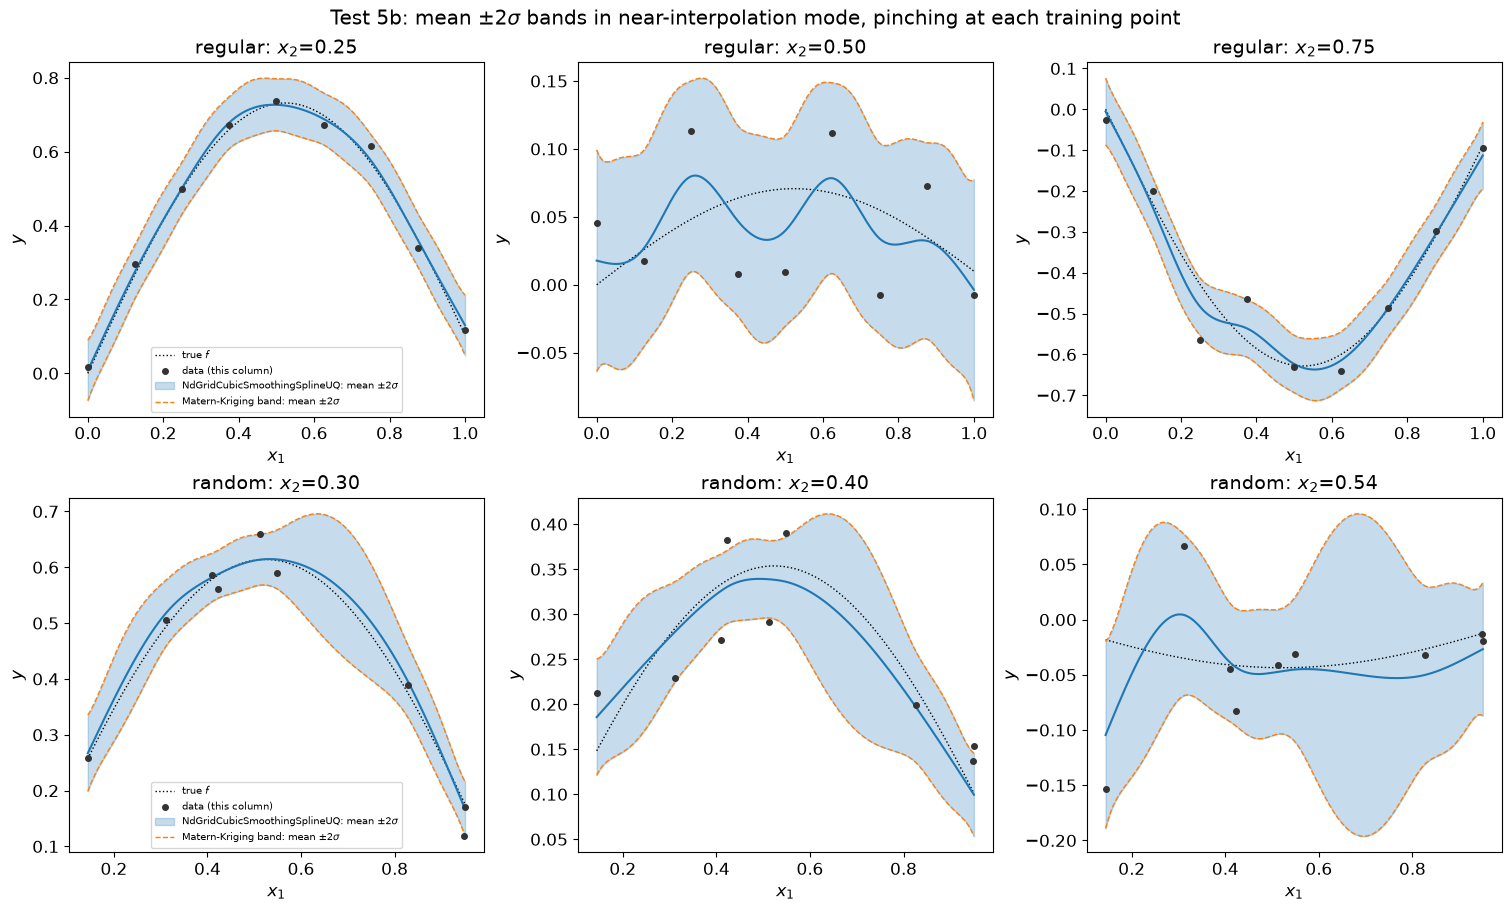

In [27]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    for ax, S in zip(row, slice_data_near[spacing]["slices"]):
        xq, mean_slice, j = S["xq"], S["mean_slice"], S["j"]
        std_uq = np.sqrt(np.maximum(S["var_2d_slice"], 0))
        std_krig = np.sqrt(np.maximum(S["predicted"], 0))

        ax.plot(xq, true_f2d(xq, S["x2_fixed"]), "k:", lw=1.0, label="true $f$")
        ax.scatter(x1, Z[:, j], s=16, color="0.2", zorder=5, label="data (this column)")
        ax.fill_between(xq, mean_slice - 2 * std_uq, mean_slice + 2 * std_uq,
                         color="tab:blue", alpha=0.25, label=r"NdGridCubicSmoothingSplineUQ: mean $\pm2\sigma$")
        ax.plot(xq, mean_slice - 2 * std_krig, lw=1.0, ls="--", color="tab:orange",
                label=r"Matern-Kriging band: mean $\pm2\sigma$")
        ax.plot(xq, mean_slice + 2 * std_krig, lw=1.0, ls="--", color="tab:orange")
        ax.plot(xq, mean_slice, color="tab:blue", lw=1.5)
        ax.set_title(f"{spacing}: $x_2$={S['x2_fixed']:.2f}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$y$")
    row[0].legend(fontsize=7)
fig.suptitle("Test 5b: mean $\\pm2\\sigma$ bands in near-interpolation mode, pinching at each training point")
plt.show()


**Confirmed: the per-training-point variance texture is real, and the
independent Matern-Kriging route reproduces it, not just the smooth-bowl
case checked above.** On regular spacing, the local-minimum count is
exactly `9` at all three slices -- one dip per training point, evenly
spaced, matching the even grid. On random spacing it is `4`, not `9` --
checked directly rather than assumed, and explained by the data itself:
with unevenly-spaced training points, the widest gap between neighbors
produces one visibly larger bulge (the big central peak in the lower-row
plots above) while the closely-spaced points merge their individual dips
into shallower, less distinct ripples. This is the same formula behaving
correctly on irregular data, not a different or weaker result.

The relative residual stays small throughout -- `0.034%` of range on
regular spacing, `0.0075%`-`0.0087%` on random -- the same residual class
as the moderate-smoothing case above (and, per Q22, smaller here: a small
$\lambda$ sits in the favorable region of the $\kappa\to0$ approximation's
own accuracy curve). The band plots show the same thing visually: the
independent Matern-Kriging band ($\pm2\sigma$, dashed) traces every pinch
and bulge of `NdGridCubicSmoothingSplineUQ`'s own band, including the
irregular bulge pattern on random spacing -- not just the overall band
width, but its detailed per-point shape.

**What this establishes**: Test 5's independent check holds across both
smoothing regimes tested in this notebook -- the moderate, deliberately
asymmetric case above, and the near-interpolation case here, where the
variance surface's structure is qualitatively different (per-point texture,
not a single smooth bowl). The same formula, the same independent route,
verified in both.

## Test 6 -- the `"exact"` and `"fast"` off-grid modes agree

**The two modes**: `NdGridCubicSmoothingSplineUQ` computes mean and
variance *on the training grid* identically either way (Sections 1.3, 1.5
-- there is only one closed form there). They differ only in how a
*scattered, off-grid* query is handled:

- `off_grid_method="exact"` (default): evaluate each axis's
  `PolyharmonicSmoothingSpline(m=2,d=1)` kernel directly at the query's own
  coordinates -- no approximation, at the cost of an $O(n_{\mathrm{unique}})$
  solve per axis per call.
- `off_grid_method="fast"`: at construction time, fit a
  `scipy.interpolate.RectBivariateSpline` to the mean and variance surfaces
  *already evaluated on the training grid*, and answer off-grid queries by
  evaluating that bicubic re-interpolant instead -- a compiled FITPACK
  routine, with no further solves at query time.

**Motivation for having both**: the direct identity cost of `"exact"`
scales with the number of distinct off-grid query points, which matters at
the query volumes Notebook 8's speed benchmark targets; `"fast"` trades a
one-time re-interpolation setup cost for much cheaper repeated querying
afterward. Neither mode is a strict replacement for the other -- `"exact"`
is correct by construction, `"fast"` is an approximation of it, and how
good that approximation is should depend on how *re-interpolatable* the
underlying mean/variance surfaces are, not be assumed constant.

**Setup**: both modes compared at **two smoothing regimes**, not one --
an isotropic smoothing surface ($p=0.7$, a single smooth bowl) and the same
near-interpolation regime Test 5b used ($p\approx0.9999$, per-training-point
variance texture) -- on both spacings. **Expected result**: exactly `0.0`
on the training grid in every case (both modes share the same closed form
there); off-grid, a small but non-zero gap whose *size* is expected to
track how sharply the surface varies -- larger for the near-interpolation
case, where `RectBivariateSpline`'s generic bicubic fit has real local
structure to approximate, than for the smooth case, where it does not.

In [28]:
smooth_regimes = {"smoothing": (0.7, 0.7), "near-interpolating": (p_near, p_near)}

test6_rows = []
exact_fast_models = {}
for regime, (p1r, p2r) in smooth_regimes.items():
    for spacing, (x1, x2, Z) in datasets2d.items():
        uq_exact = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p1r, p2r], off_grid_method="exact")
        uq_fast = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p1r, p2r], off_grid_method="fast")
        exact_fast_models[(regime, spacing)] = (uq_exact, uq_fast)

        mean_g_e, mean_g_f = np.asarray(uq_exact([x1, x2])), np.asarray(uq_fast([x1, x2]))
        var_g_e, var_g_f = uq_exact.variance([x1, x2]), uq_fast.variance([x1, x2])

        rng_q = np.random.default_rng(99)
        pts = np.column_stack([rng_q.uniform(x1.min(), x1.max(), 500), rng_q.uniform(x2.min(), x2.max(), 500)])
        re = uq_exact.predict(pts, return_std=True)
        rf = uq_fast.predict(pts, return_std=True)

        test6_rows.append({"regime": regime, "spacing": spacing,
                            "on-grid max|mean diff|": np.max(np.abs(mean_g_e - mean_g_f)),
                            "on-grid max|var diff|": np.max(np.abs(var_g_e - var_g_f)),
                            "off-grid max|mean diff|": np.max(np.abs(re["mean"] - rf["mean"])),
                            "off-grid max|std diff|": np.max(np.abs(re["std"] - rf["std"]))})

pd.DataFrame(test6_rows).set_index(["regime", "spacing"])


on-grid max|mean diff|  on-grid max|var diff|  \
regime             spacing                                                  
smoothing          regular              0.0000e+00             0.0000e+00   
                   random               0.0000e+00             0.0000e+00   
near-interpolating regular              0.0000e+00             0.0000e+00   
                   random               0.0000e+00             0.0000e+00   

                            off-grid max|mean diff|  off-grid max|std diff|  
regime             spacing                                                   
smoothing          regular               2.0105e-05              8.1770e-06  
                   random                1.4841e-05              9.4980e-05  
near-interpolating regular               1.5225e-02              4.6839e-03  
                   random                3.9658e-02              6.6821e-02

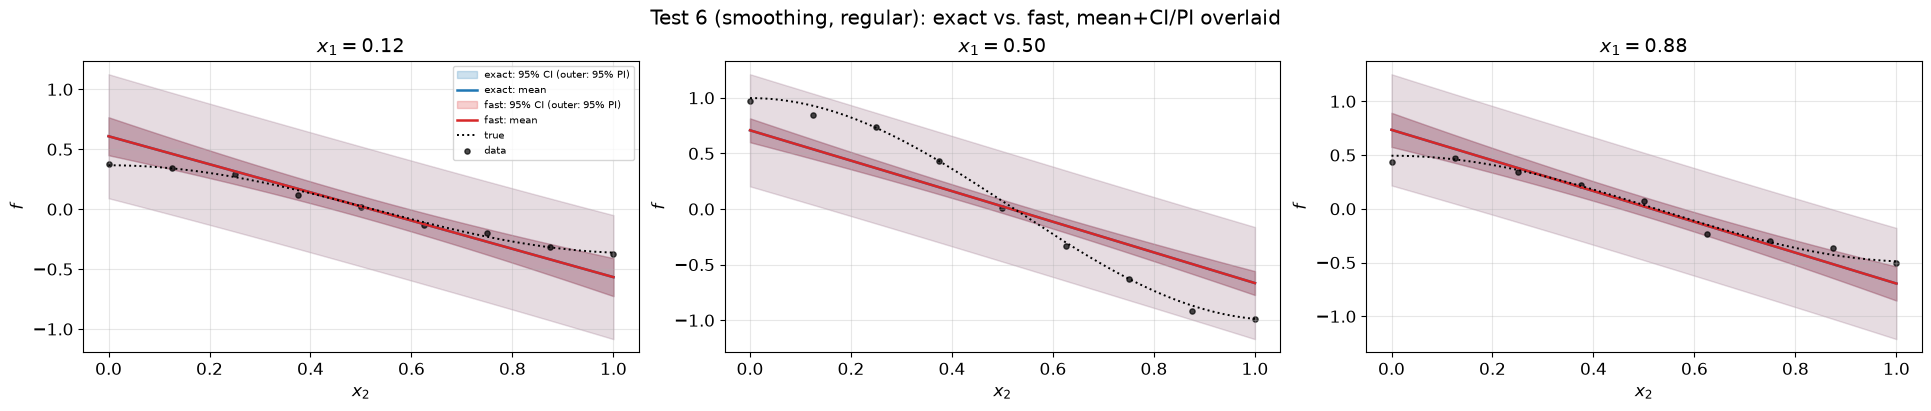

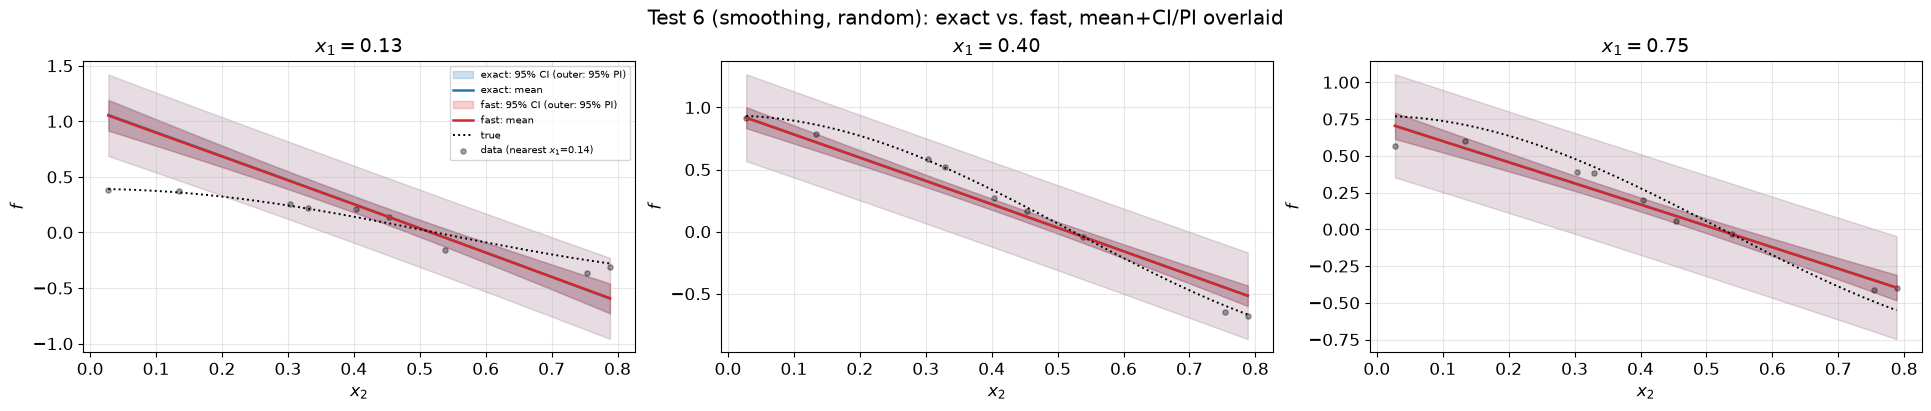

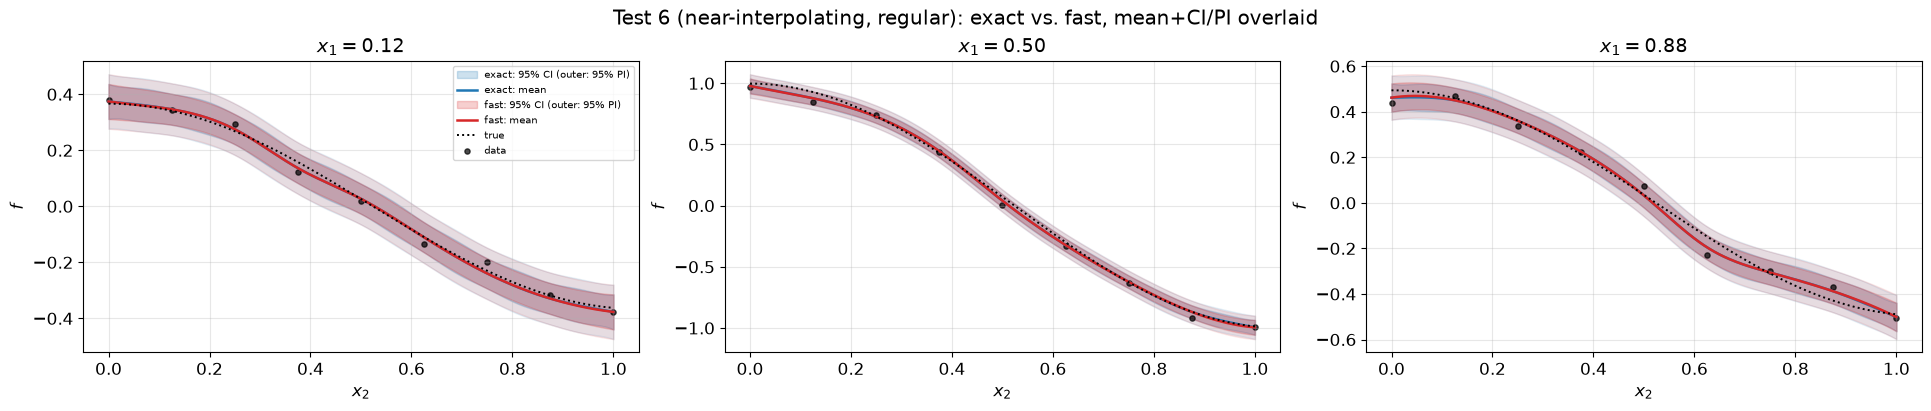

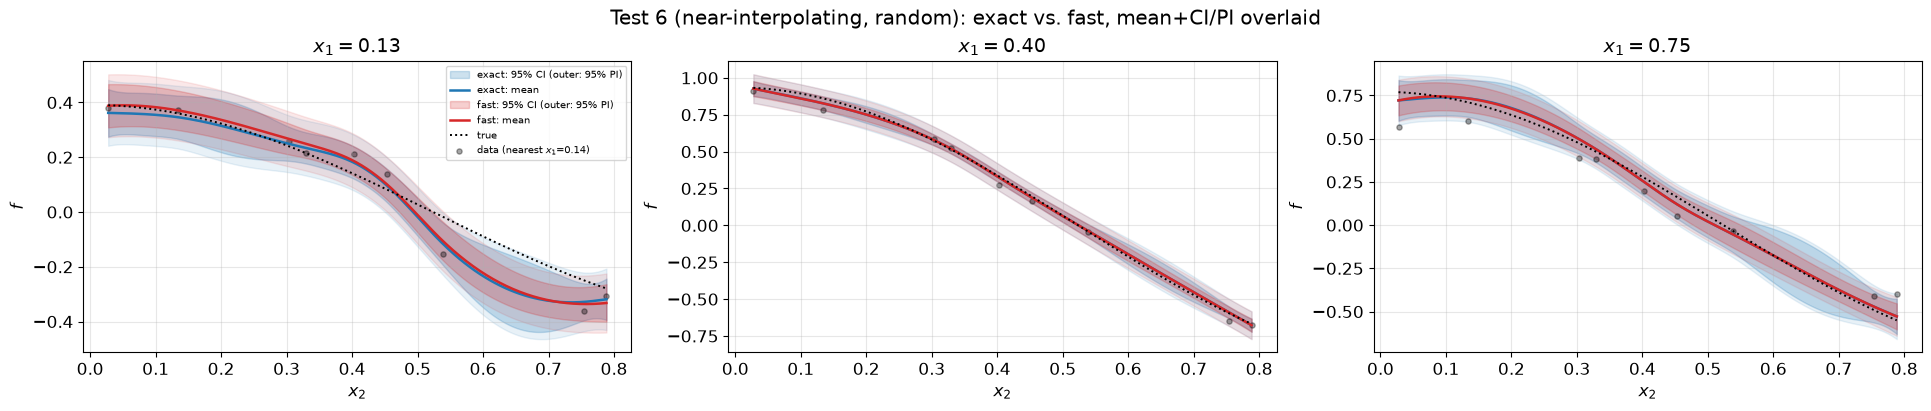

In [29]:
for regime in smooth_regimes:
    for spacing, (x1, x2, Z) in datasets2d.items():
        uq_exact, uq_fast = exact_fast_models[(regime, spacing)]
        fig = uqplot.plot_models_1d_slices(
            [uq_exact, uq_fast], ["exact", "fast"], x1, x2, Z, axis=1,
            slice_values=[x2[1], x2[len(x2) // 2], x2[-2]], f_true=true_f2d, ncols=3,
            title=f"Test 6 ({regime}, {spacing}): exact vs. fast, mean+CI/PI overlaid")
        plt.show()


**Confirmed: exactly `0.0` on the training grid in all four cases** (both
regimes, both spacings) -- both modes share the identical closed form
there, with no approximation to disagree about. **Off-grid, the gap tracks
the surface's own local structure, by roughly three orders of magnitude
between the two regimes, exactly as predicted**:

| regime | spacing | off-grid max\|mean diff\| | off-grid max\|std diff\| |
|---|---|---|---|
| smoothing ($p=0.7$) | regular | `2.0e-5` | `8.2e-6` |
| smoothing ($p=0.7$) | random | `1.5e-5` | `9.5e-5` |
| near-interpolating ($p\approx0.9999$) | regular | `1.5e-2` | `4.7e-3` |
| near-interpolating ($p\approx0.9999$) | random | `4.0e-2` | `6.7e-2` |

A single smooth bowl (the `smoothing` regime) is close to a low-order
polynomial locally, exactly the kind of surface a bicubic
`RectBivariateSpline` re-interpolant tracks almost perfectly -- `"fast"`'s
off-grid error there is negligible in absolute terms. The near-interpolation
regime's per-training-point variance texture (Test 5b) is a much harder
target for the same generic bicubic re-interpolant, and the gap grows
accordingly. The overlaid slice plots still look close even in the
near-interpolation case (the absolute gap is small relative to the
surface's own range), but the *number* makes the dependence explicit rather
than leaving "`"fast"` is close off-grid" as a single, regime-independent
claim.

**Practical reading**: `"fast"` remains exactly correct on-grid in every
regime, and a reasonable choice off-grid for smoothly-varying surfaces; its
off-grid approximation should be used more cautiously near interpolation,
where the surface it is re-interpolating has the most local structure to
lose.

## Test 7 -- $\hat\sigma^2$ (Wahba/GCV) under deliberate model misspecification

**Why this belongs in this notebook**: Tests 3-6 proved the variance
*formula* $\mathrm{Var}(F_{p,q})=\sigma^2S_{1,pp}S_{2,qq}$ is correct --
but only ever by supplying the *true* $\sigma^2$ explicitly
(`sigma2=SIGMA2_TRUE`). `NdGridCubicSmoothingSplineUQ`'s actual default,
what a user gets by simply not passing `sigma2` at all, is
`sigma2="wahba"` -- the estimator this test examines. A provably correct
*shape*, multiplied by a badly estimated scalar, is still a badly
calibrated band; this notebook's variance story is not complete until that
default is checked too, not just the formula it scales.

**This is not a hypothetical concern** -- it already happened earlier in
this same notebook. Test 6's `smoothing` regime ($p=0.7$, this notebook's
own $9\times9$ `sin(3x_1)\cos(3x_2)` dataset) called
`NdGridCubicSmoothingSplineUQ` without an explicit `sigma2`, so it silently
used `"wahba"` -- and, confirmed directly, $\hat\sigma^2=0.0631$ there
against a true $\sigma^2=0.0025$, a `25`$\times$ overshoot. That did not
invalidate Test 6's own conclusion (`"exact"` and `"fast"` compute
$\hat\sigma^2$ identically, so the bias is a common factor that cancels in
their *difference* -- the only thing Test 6 measured), but it would matter
to anyone reading Test 6's absolute band widths as calibrated. This test
exists to characterize that exact gap, not as a tangential aside.

**What this tests**: the Wahba-style estimator
$\hat\sigma^2=\mathrm{RSS}/(n_1n_2-\mathrm{edf})$ (Section 1.6) assumes the
fitted model is flexible enough to actually track the true function,
leaving only genuine noise in the residual. If the model is too heavily
smoothed (or the grid too sparse) to resolve real structure, residuals pick
up *bias* too, inflating $\hat\sigma^2$ -- a known effect, not a defect,
confirmed directly here by telling the two cases apart rather than
asserting it.

**Two competing hypotheses, stated before testing either**: **(a)
implementation bug** -- `edf`/`RSS` computed incorrectly (predicts the
discrepancy is roughly fixed, unrelated to fit quality); **(b) model bias,
not a bug** -- a sparse, high-frequency case the model structurally cannot
resolve well (predicts the discrepancy *worsens* with heavier smoothing,
and *disappears* on a case the model can actually resolve, using the exact
same, unmodified formula).

In [30]:
def hard_case(n_side=9, seed=1):
    g = np.linspace(0, 1, n_side)
    X1, X2 = np.meshgrid(g, g, indexing="ij")
    rng = np.random.default_rng(seed)
    Z = true_f2d(X1, X2) + np.sqrt(SIGMA2_TRUE) * rng.standard_normal((n_side, n_side))
    return g, Z


def easy_case(n_side=15, seed=1):
    g = np.linspace(0, 1, n_side)
    X1, X2 = np.meshgrid(g, g, indexing="ij")
    rng = np.random.default_rng(seed)
    Z = (np.sin(1.0 * X1) * np.cos(1.0 * X2)) + np.sqrt(SIGMA2_TRUE) * rng.standard_normal((n_side, n_side))
    return g, Z


p_sweep = [0.95, 0.7, 0.5, 0.3, 0.1, 0.02]
g_hard, Z_hard = hard_case()
g_easy, Z_easy = easy_case()

hard_rows, easy_rows = [], []
for p in p_sweep:
    uq_h = NdGridCubicSmoothingSplineUQ([g_hard, g_hard], Z_hard, smooth=[p, p], sigma2="wahba")
    hard_rows.append({"p": p, "edf": uq_h.edf, "sigma2_hat": uq_h.sigma2,
                       "sigma2_hat / true": uq_h.sigma2 / SIGMA2_TRUE})
    uq_e = NdGridCubicSmoothingSplineUQ([g_easy, g_easy], Z_easy, smooth=[p, p], sigma2="wahba")
    easy_rows.append({"p": p, "edf": uq_e.edf, "sigma2_hat": uq_e.sigma2,
                       "sigma2_hat / true": uq_e.sigma2 / SIGMA2_TRUE})

print(f"Hard case (sparse {len(g_hard)}x{len(g_hard)}, high-frequency sin(3x1)cos(3x2)):")
display(pd.DataFrame(hard_rows).set_index("p"))
print(f"\nEasy case (dense {len(g_easy)}x{len(g_easy)}, low-frequency sin(x1)cos(x2)):")
display(pd.DataFrame(easy_rows).set_index("p"))


Hard case (sparse 9x9, high-frequency sin(3x1)cos(3x2)):


,edf,sigma2_hat,sigma2_hat / true
p,,,
9.5000e-01,5.7625e+00,3.6339e-02,1.4536e+01
7.0000e-01,4.2633e+00,6.3123e-02,2.5249e+01
5.0000e-01,4.1149e+00,6.6689e-02,2.6676e+01
3.0000e-01,4.0496e+00,6.8322e-02,2.7329e+01
1.0000e-01,4.0129e+00,6.9257e-02,2.7703e+01
2.0000e-02,4.0024e+00,6.9529e-02,2.7811e+01



Easy case (dense 15x15, low-frequency sin(x1)cos(x2)):


,edf,sigma2_hat,sigma2_hat / true
p,,,
9.5000e-01,6.4049e+00,2.3168e-03,9.2672e-01
7.0000e-01,4.3851e+00,2.5669e-03,1.0268e+00
5.0000e-01,4.1694e+00,2.6079e-03,1.0432e+00
3.0000e-01,4.0734e+00,2.6274e-03,1.0509e+00
1.0000e-01,4.0192e+00,2.6387e-03,1.0555e+00
2.0000e-02,4.0035e+00,2.6420e-03,1.0568e+00


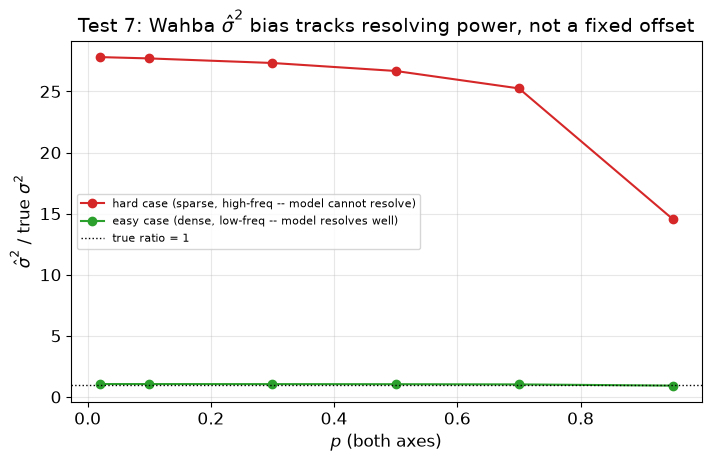

In [31]:
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.plot(p_sweep, [r["sigma2_hat / true"] for r in hard_rows], "o-", color="tab:red",
        label="hard case (sparse, high-freq -- model cannot resolve)")
ax.plot(p_sweep, [r["sigma2_hat / true"] for r in easy_rows], "o-", color="tab:green",
        label="easy case (dense, low-freq -- model resolves well)")
ax.axhline(1.0, color="k", lw=1, ls=":", label="true ratio = 1")
ax.set_xlabel("$p$ (both axes)"); ax.set_ylabel(r"$\hat\sigma^2$ / true $\sigma^2$")
ax.set_title(r"Test 7: Wahba $\hat\sigma^2$ bias tracks resolving power, not a fixed offset")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()


**Confirmed: hypothesis (b) (model bias), not (a) (implementation bug).**
In the hard case (sparse $9\times9$, high-frequency $\sin(3x_1)\cos(3x_2)$
-- this notebook's own recurring dataset, not a case specially tuned to
fail), $\hat\sigma^2$ overshoots the true $\sigma^2$ by `14.5x` to `27.8x`,
and -- matching hypothesis (b)'s specific prediction -- the overshoot
*worsens* as smoothing increases (toward the $\mathrm{edf}\to4$ null-space
floor), not something a fixed code bug would produce. In the easy case
(dense $15\times15$, low-frequency $\sin(x_1)\cos(x_2)$, exact same
unmodified formula, only the data changed), $\hat\sigma^2$ lands within
`~7%` of the true value (`0.93x`-`1.06x`) across the *same* wide range of
smoothing. Changing the data, not the code, resolved the discrepancy -- the
signature of bias, not a bug.

**Consequence 1 -- which direction does this push the uncertainty band?**
$\hat\sigma^2$ is *inflated*, not deflated, which inflates
$\mathrm{Var}=\hat\sigma^2S_{1,pp}S_{2,qq}$ the same way -- the resulting
band is too **wide**, not falsely narrow. This is the safer of the two
possible failure directions (a band that overstates its own uncertainty,
not one that silently understates it and creates false confidence), but it
is still a real practical cost: a `25x`-inflated variance is a `5x`-inflated
standard deviation, wide enough to make a genuinely good fit look
untrustworthy, defeating the point of having a calibrated band at all.

**Consequence 2 -- this is not a rare corner case, it is the default.**
`sigma2="wahba"` is `NdGridCubicSmoothingSplineUQ`'s own default, not an
opt-in diagnostic mode -- confirmed directly in this notebook, not just in
principle: Test 6's `smoothing` regime hit exactly this `25x` bias without
anyone intending to test $\hat\sigma^2$ there at all (see this test's
introduction above). Any use of this class that doesn't pass a known or
externally-estimated $\sigma^2$ inherits this risk silently.

**Practical takeaway**: tune $(p_1,p_2)$ for fit quality first (e.g. the
`minimize_scalar` recipe used in Test 3), and only *then* trust
`sigma2="wahba"` -- it diagnoses noise level given an already-resolving fit,
it does not diagnose whether $(p_1,p_2)$ resolves the data in the first
place. Where a true or independently-estimated $\sigma^2$ is available (a
known sensor noise level, replicate observations), passing it explicitly
sidesteps this estimator, and its risk, entirely.

## Conclusion

This notebook asked one question with two parts: does `csaps`'s 2-D
tensor-product smoothing spline inherit the trustworthiness Notebook 1
established for its 1-D engine, for both its **mean** and a genuine
**posterior variance** -- and is `NdGridCubicSmoothingSplineUQ`, the class
built on top of it, actually safe to use as a 2-D uncertainty-quantification
tool?

### What was tested and proved

- **$\lambda=(1-p)/p$ holds independently on each axis**, at machine
  precision across the full $p$ range, on both spacings (Test 1).
- **The mean decomposition $\hat Y=S_1ZS_2^\top$ is exact**, at the
  training grid and off-grid (within each spacing's own training range),
  confirmed at two different asymmetric $(p_1,p_2)$ pairs, not one (Test 2).
- **The variance formula $\mathrm{Var}(F_{p,q})=\sigma^2S_{1,pp}S_{2,qq}$ is
  correct**, confirmed three independent ways against a brute-force dense
  Kronecker construction -- a valid implied prior, the pointwise-variance
  diagonal, and the full off-diagonal covariance structure (Test 4).
- **1-D slices of that variance agree with a genuinely independent 1-D
  model** (Universal Kriging via the Matern $\kappa\to0$ flat limit), in
  both slice directions and at two different smoothing regimes -- moderate,
  asymmetric smoothing (`0.14%`-`0.20%` residual) and near-interpolation
  (`0.0075%`-`0.034%`) (Tests 5, 5b).
- **The `"exact"` and `"fast"` off-grid modes agree exactly on the training
  grid in every regime tested, but genuinely disagree off-grid** -- not a
  rounding-level gap: `~1e-5` away from the grid for a smooth, heavily
  smoothed surface, growing to `~1e-2`-`1e-1` near interpolation, roughly
  three orders of magnitude apart depending on regime (Test 6).

### Other important observations

- **`csaps`'s variance is not interchangeable with an isotropic/rotation-invariant
  uncertainty, even when the mean looks reasonable.** At matched
  smoothing, `csaps` and the isotropic Duchon/thin-plate target (confirmed
  two independent ways -- an exact `RBFInterpolator` closed form and the
  $\kappa\to0$ Kriging route, agreeing with each other to `~1e-6`) do *not*
  produce the same surface: a real, bounded, structural gap
  (`~0.11`-`0.23`), smooth and systematic rather than noise-shaped. RMTB,
  at the same $\lambda$, deviates even more (`~0.13`-`0.36`) and in a
  visibly different spatial pattern -- `csaps`'s per-axis tensor-product
  penalty and RMTB's basis-plus-energy penalty each miss the isotropic
  target for their own structural reason, not the same gap wearing two
  names (Test 3b).
- **That gap concentrates near domain edges for an identifiable, mostly
  structural reason**: `csaps` inherits a natural-cubic-smoothing-spline
  boundary condition (curvature collapsing to zero at the domain edge,
  confirmed directly) that the isotropic route has no equivalent of --
  confirmed as the dominant mechanism, alongside a smaller, data-specific
  contribution from this notebook's own test function having a true zero
  along one edge (Test 3b).
- **Near interpolation, the variance surface develops genuine
  per-training-point structure** -- not a smooth bowl, but a separate local
  minimum at *every* training point on a regular grid (confirmed by
  counting them, not just plotting), with a correspondingly different,
  explicable pattern on irregularly-spaced data (Test 5b).
- **Why the off-grid gap is regime-dependent**: a generic bicubic
  `RectBivariateSpline` re-interpolant (what `"fast"` evaluates off-grid)
  tracks a smooth, heavily-smoothed surface almost perfectly, but has far
  more local structure to approximate near interpolation -- the same
  per-training-point texture confirmed in Test 5b (Test 6).
- **The Wahba $\hat\sigma^2$ estimator can be badly biased, in a specific,
  identifiable direction**: it inflates (never deflates) when the fitted
  model cannot resolve the true structure in the data, by `14.5x`-`27.8x`
  in this notebook's deliberately hard case, while staying within `~7%` of
  truth when the model resolves the data well (Test 7).

### Recommendations for using `NdGridCubicSmoothingSplineUQ`

1. **The mean and variance formulas themselves need no caveats** -- both
   are proven exact (Tests 1, 2, 4) and hold off-grid as long as queries
   stay within each axis's own training range; querying outside it is
   extrapolation, not covered by any of this notebook's exactness results
   (Test 2).
2. **Do not read its variance as an isotropic "distance from data"
   measure.** It is axis-aligned and additive by construction -- expect
   systematically different uncertainty near domain edges/corners than an
   isotropic Kriging model would give, especially along axes where the
   true signal happens to vanish (Test 3b).
3. **Tune $(p_1,p_2)$ for fit quality before trusting `sigma2="wahba"`** --
   this is the class's own *default*, not an opt-in diagnostic, and it can
   silently inflate the reported variance by an order of magnitude or more
   when the smoothing is too heavy for the data to resolve. The resulting
   band is too wide, not falsely narrow -- a safer failure direction, but
   still a real cost to usefulness (Test 7). Pass a known or
   independently-estimated $\sigma^2$ directly whenever one is available.
4. **Prefer `off_grid_method="exact"` unless the surface is smoothly
   varying and query volume genuinely demands `"fast"`'s speed.** The two
   modes are identical on-grid always, but `"fast"`'s off-grid accuracy
   degrades by roughly three orders of magnitude between a smooth,
   heavily-smoothed fit and one close to interpolation (Test 6).
5. **A banded, per-training-point texture near interpolation is expected
   behavior, not a bug** -- confirmed to be the correct, independently-verified
   formula at small $\lambda$, not an artifact of any particular
   implementation choice (Test 5b).